In [1]:
# # ===============================
# # 1. Imports
# # ===============================
# import pandas as pd
# import os 
# import joblib
# import numpy as np
# import matplotlib.pyplot as plt
# import random as rn
# from sklearn.preprocessing import StandardScaler, LabelEncoder
# from sklearn.model_selection import train_test_split
# from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
# from tensorflow.keras import Sequential
# from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
# from tensorflow.keras.utils import to_categorical
# from tensorflow.keras.callbacks import ModelCheckpoint
# import tensorflow as tf

# # Set random seeds
# def set_seed(): 
#     SEED = 0 
#     os.environ['PYTHONHASHSEED'] = str(SEED)
#     os.environ['TF_DETERMINISTIC_OPS'] = '1'
#     np.random.seed(SEED)
#     tf.random.set_seed(SEED)
#     rn.seed(SEED)

# set_seed()

# # ===============================
# # 2. Load data
# # ===============================
# data = pd.read_csv('/kaggle/input/up-fall-dataset/CompleteDataSet.csv')
# data.ffill(inplace=True)
# data.bfill(inplace=True)

# # ===============================
# # 3. Select only numeric columns (sensor data)
# # ===============================
# sensor_columns = data.select_dtypes(include=[np.number]).columns.tolist()
# X = data[sensor_columns].values

# # Encode labels
# le = LabelEncoder()
# y = le.fit_transform(data['Activity'].values)  # Only Activity column as target
# num_classes = len(le.classes_)

# # ===============================
# # 4. Split the data
# # ===============================
# X_train, X_test, y_train, y_test = train_test_split(
#     X, y, test_size=0.2, random_state=42, stratify=y
# )

# X_train, X_val, y_train, y_val = train_test_split(
#     X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
# )

# # ===============================
# # 5. Scale features
# # ===============================
# scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train)
# X_val_scaled = scaler.transform(X_val)
# X_test_scaled = scaler.transform(X_test)

# joblib.dump(scaler, '/kaggle/working/scaler.pkl')

# # Convert labels to categorical
# Y_train = to_categorical(y_train, num_classes)
# Y_val = to_categorical(y_val, num_classes)
# Y_test = to_categorical(y_test, num_classes)

# # ===============================
# # 6. Define MLP model
# # ===============================
# def create_mlp(input_shape, num_classes):
#     model = Sequential([
#         Dense(2000, activation='relu', input_shape=(input_shape,)),
#         BatchNormalization(),
#         Dense(600, activation='relu'),
#         BatchNormalization(),
#         Dropout(0.2),
#         Dense(num_classes, activation='softmax')
#     ])
#     model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
#     return model

# model = create_mlp(X_train_scaled.shape[1], num_classes)
# model.summary()

# # ===============================
# # 7. Train model with checkpoint
# # ===============================
# checkpoint = ModelCheckpoint(
#     '/kaggle/working/best_model.h5', monitor='val_accuracy',
#     save_best_only=True, verbose=1, mode='max'
# )

# history = model.fit(
#     X_train_scaled, Y_train,
#     validation_data=(X_val_scaled, Y_val),
#     epochs=50, batch_size=256,
#     callbacks=[checkpoint]
# )

# # Load best model
# model.load_weights('/kaggle/working/best_model.h5')

# # ===============================
# # 8. Evaluate model
# # ===============================
# test_loss, test_accuracy = model.evaluate(X_test_scaled, Y_test)
# print(f"Test Loss: {test_loss}, Test Accuracy: {test_accuracy}")

# y_pred_classes = np.argmax(model.predict(X_test_scaled), axis=1)
# y_true_classes = np.argmax(Y_test, axis=1)

# print(f"Accuracy: {accuracy_score(y_true_classes, y_pred_classes)}")
# print(f"Precision: {precision_score(y_true_classes, y_pred_classes, average='weighted')}")
# print(f"Recall: {recall_score(y_true_classes, y_pred_classes, average='weighted')}")
# print(f"F1 Score: {f1_score(y_true_classes, y_pred_classes, average='weighted')}")


In [2]:
# import numpy as np
# import joblib
# from tensorflow.keras.models import load_model

# # Load model and scaler
# model = load_model('/kaggle/working/best_model.h5')
# scaler = joblib.load('/kaggle/working/scaler.pkl')

# # Generate dummy input matching the model's input size
# input_size = model.input_shape[1]  # number of features
# dummy_input = np.random.randn(1, input_size)  # random values with shape (1, input_size)

# # Scale the dummy input
# dummy_input_scaled = scaler.transform(dummy_input)

# # Predict
# pred_probs = model.predict(dummy_input_scaled)
# pred_class = np.argmax(pred_probs, axis=1)[0]

# activity_map = {
#     0: 'Falling hands', 
#     1: 'Falling knees', 
#     2: 'Falling backwards', 
#     3: 'Falling sideward',
#     4: 'Falling chair', 
#     5: 'Walking', 
#     6: 'Standing', 
#     7: 'Sitting', 
#     8: 'Picking object', 
#     9: 'Jumping', 
#     10: 'Laying'
# }

# print("Predicted Activity:", activity_map[pred_class])


In [3]:
# # ============================================
# # TinyML Activity Recognition for UP-Fall
# # Single-cell script
# # ============================================

# # 1. Imports
# import os
# import random as rn
# import numpy as np
# import pandas as pd
# import joblib
# import matplotlib.pyplot as plt

# from sklearn.preprocessing import StandardScaler, LabelEncoder
# from sklearn.model_selection import train_test_split
# from sklearn.metrics import (
#     accuracy_score,
#     f1_score,
#     precision_score,
#     recall_score,
#     confusion_matrix,
#     classification_report
# )

# import tensorflow as tf
# from tensorflow.keras import Sequential
# from tensorflow.keras.layers import Dense
# from tensorflow.keras.utils import to_categorical

# # ============================================
# # 2. Reproducibility
# # ============================================
# def set_seed(seed=0):
#     os.environ['PYTHONHASHSEED'] = str(seed)
#     os.environ['TF_DETERMINISTIC_OPS'] = '1'
#     np.random.seed(seed)
#     rn.seed(seed)
#     tf.random.set_seed(seed)

# set_seed(0)

# # ============================================
# # 3. Load data
# # ============================================
# # Adjust the path if needed
# data_path = '/kaggle/input/up-fall-dataset/CompleteDataSet.csv'
# data = pd.read_csv(data_path)

# # Simple cleaning: forward/backward fill missing
# data.ffill(inplace=True)
# data.bfill(inplace=True)

# # ============================================
# # 4. Feature / label preparation
# # ============================================
# # Numeric sensor columns (features)
# sensor_columns = data.select_dtypes(include=[np.number]).columns.tolist()
# X = data[sensor_columns].values

# # Activity labels (target)
# le = LabelEncoder()
# y = le.fit_transform(data['Activity'].values)
# num_classes = len(le.classes_)

# print("Classes:", list(le.classes_))
# print("Number of classes:", num_classes)
# print("Feature dim:", X.shape[1])

# # ============================================
# # 5. Train/Val/Test split
# # ============================================
# X_train, X_test, y_train, y_test = train_test_split(
#     X, y, test_size=0.2, random_state=42, stratify=y
# )

# X_train, X_val, y_train, y_val = train_test_split(
#     X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
# )

# print("Train shape:", X_train.shape)
# print("Val shape:", X_val.shape)
# print("Test shape:", X_test.shape)

# # ============================================
# # 6. Scaling
# # ============================================
# scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train)
# X_val_scaled   = scaler.transform(X_val)
# X_test_scaled  = scaler.transform(X_test)

# joblib.dump(scaler, 'scaler_tiny.pkl')
# print("Scaler saved as scaler_tiny.pkl")

# # One-hot encode labels
# Y_train = to_categorical(y_train, num_classes)
# Y_val   = to_categorical(y_val, num_classes)
# Y_test  = to_categorical(y_test, num_classes)

# # ============================================
# # 7. TinyML MLP model definition
# # ============================================
# def create_tiny_mlp(input_dim, num_classes):
#     model = Sequential([
#         Dense(64, activation='relu', input_shape=(input_dim,)),
#         Dense(32, activation='relu'),
#         Dense(num_classes, activation='softmax')
#     ])
#     model.compile(
#         optimizer='adam',
#         loss='categorical_crossentropy',
#         metrics=['accuracy']
#     )
#     return model

# input_dim = X_train_scaled.shape[1]
# model = create_tiny_mlp(input_dim, num_classes)
# model.summary()

# # ============================================
# # 8. Training
# # ============================================
# checkpoint_path = 'tiny_activity_model_best.h5'
# checkpoint_cb = tf.keras.callbacks.ModelCheckpoint(
#     checkpoint_path,
#     monitor='val_accuracy',
#     save_best_only=True,
#     mode='max',
#     verbose=1
# )

# history = model.fit(
#     X_train_scaled, Y_train,
#     validation_data=(X_val_scaled, Y_val),
#     epochs=50,
#     batch_size=256,
#     callbacks=[checkpoint_cb],
#     verbose=1
# )

# # Load best weights
# model.load_weights(checkpoint_path)
# print("Loaded best model weights from", checkpoint_path)

# # ============================================
# # 9. Evaluation on test set
# # ============================================
# test_loss, test_acc = model.evaluate(X_test_scaled, Y_test, verbose=0)
# print(f"\n=== Test metrics ===")
# print(f"Test Loss: {test_loss:.4f}")
# print(f"Test Accuracy: {test_acc:.4f}")

# # Predictions
# y_pred_probs   = model.predict(X_test_scaled, verbose=0)
# y_pred_classes = np.argmax(y_pred_probs, axis=1)
# y_true_classes = y_test.copy()

# acc  = accuracy_score(y_true_classes, y_pred_classes)
# prec = precision_score(y_true_classes, y_pred_classes, average='weighted', zero_division=0)
# rec  = recall_score(y_true_classes, y_pred_classes, average='weighted', zero_division=0)
# f1   = f1_score(y_true_classes, y_pred_classes, average='weighted', zero_division=0)

# print("\n=== Detailed test metrics (weighted) ===")
# print(f"Accuracy : {acc:.4f}")
# print(f"Precision: {prec:.4f}")
# print(f"Recall   : {rec:.4f}")
# print(f"F1 Score : {f1:.4f}")

# print("\n=== Classification report (per class) ===")
# class_names = [str(c) for c in le.classes_]
# print(classification_report(y_true_classes, y_pred_classes, target_names=class_names))



# # ============================================
# # 10. Training curves
# # ============================================
# plt.figure(figsize=(12,5))

# # Accuracy curve
# plt.subplot(1,2,1)
# plt.plot(history.history['accuracy'], label='Train Acc')
# plt.plot(history.history['val_accuracy'], label='Val Acc')
# plt.title('Training & Validation Accuracy')
# plt.xlabel('Epoch')
# plt.ylabel('Accuracy')
# plt.legend()
# plt.grid(True)

# # Loss curve
# plt.subplot(1,2,2)
# plt.plot(history.history['loss'], label='Train Loss')
# plt.plot(history.history['val_loss'], label='Val Loss')
# plt.title('Training & Validation Loss')
# plt.xlabel('Epoch')
# plt.ylabel('Loss')
# plt.legend()
# plt.grid(True)

# plt.tight_layout()
# plt.show()

# # ============================================
# # 11. Confusion matrix
# # ============================================
# cm = confusion_matrix(y_true_classes, y_pred_classes)
# fig, ax = plt.subplots(figsize=(8, 6))
# im = ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
# ax.figure.colorbar(im, ax=ax)
# ax.set(
#     xticks=np.arange(cm.shape[1]),
#     yticks=np.arange(cm.shape[0]),
#     xticklabels=le.classes_,
#     yticklabels=le.classes_,
#     ylabel='True label',
#     xlabel='Predicted label',
#     title='Confusion Matrix'
# )
# plt.setp(ax.get_xticklabels(), rotation=45, ha="right",
#          rotation_mode="anchor")

# thresh = cm.max() / 2.
# for i in range(cm.shape[0]):
#     for j in range(cm.shape[1]):
#         ax.text(j, i, format(cm[i, j], 'd'),
#                 ha="center", va="center",
#                 color="white" if cm[i, j] > thresh else "black")

# fig.tight_layout()
# plt.show()

# # ============================================
# # 12. Save Keras model
# # ============================================
# keras_model_path = 'tiny_activity_model.h5'
# model.save(keras_model_path)
# print("Keras model saved as", keras_model_path)

# # Show parameter count (for paper)
# total_params = np.sum([np.prod(v.shape) for v in model.trainable_weights])
# print(f"Total trainable parameters: {total_params}")

# # ============================================
# # 13. Export to TFLite (float32 + int8 TinyML)
# # ============================================

# # Float32 TFLite
# converter = tf.lite.TFLiteConverter.from_keras_model(model)
# tflite_model = converter.convert()
# with open('tiny_activity_model.tflite', 'wb') as f:
#     f.write(tflite_model)
# print("Saved tiny_activity_model.tflite (float32)")

# # Dynamic range quantization (smaller, but not full int8)
# converter = tf.lite.TFLiteConverter.from_keras_model(model)
# converter.optimizations = [tf.lite.Optimize.DEFAULT]
# tflite_quant = converter.convert()
# with open('tiny_activity_model_quant.tflite', 'wb') as f:
#     f.write(tflite_quant)
# print("Saved tiny_activity_model_quant.tflite (dynamic range quantized)")

# # Full int8 quantization (TinyML-friendly)
# def representative_dataset():
#     for i in range(100):
#         idx = np.random.randint(0, X_train_scaled.shape[0])
#         sample = X_train_scaled[idx:idx+1].astype(np.float32)
#         yield [sample]

# converter = tf.lite.TFLiteConverter.from_keras_model(model)
# converter.optimizations = [tf.lite.Optimize.DEFAULT]
# converter.representative_dataset = representative_dataset
# converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
# converter.inference_input_type = tf.int8
# converter.inference_output_type = tf.int8

# tflite_int8 = converter.convert()
# with open('tiny_activity_model_int8.tflite', 'wb') as f:
#     f.write(tflite_int8)
# print("Saved tiny_activity_model_int8.tflite (full int8)")

# # ============================================
# # 14. Show final model sizes (for paper)
# # ============================================
# def size_kb(path):
#     return os.path.getsize(path)/1024 if os.path.exists(path) else None

# print("\n=== Model file sizes ===")
# print("Keras .h5                 :", size_kb(keras_model_path), "kB")
# print("TFLite float32            :", size_kb('tiny_activity_model.tflite'), "kB")
# print("TFLite dynamic quant      :", size_kb('tiny_activity_model_quant.tflite'), "kB")
# print("TFLite int8 (TinyML)      :", size_kb('tiny_activity_model_int8.tflite'), "kB")

# print("\nDone.")


In [4]:
# # ============================================
# # TinyML Wrist-Only Recognition for UP-Fall
# # (Multiclass 11 activities, fallback to binary fall/non-fall)
# # ============================================

# import os
# import random as rn
# import numpy as np
# import pandas as pd
# import joblib
# import matplotlib.pyplot as plt

# from sklearn.preprocessing import StandardScaler, LabelEncoder
# from sklearn.model_selection import train_test_split
# from sklearn.metrics import (
#     accuracy_score,
#     f1_score,
#     precision_score,
#     recall_score,
#     confusion_matrix,
#     classification_report
# )

# import tensorflow as tf
# from tensorflow.keras import Sequential
# from tensorflow.keras.layers import Dense
# from tensorflow.keras.utils import to_categorical

# # ============================================
# # 1. Reproducibility
# # ============================================
# def set_seed(seed=0):
#     os.environ['PYTHONHASHSEED'] = str(seed)
#     os.environ['TF_DETERMINISTIC_OPS'] = '1'
#     np.random.seed(seed)
#     rn.seed(seed)
#     tf.random.set_seed(seed)

# set_seed(0)

# # ============================================
# # 2. Load data
# # ============================================

# # If you are not sure about names, uncomment:
# # print(data.columns.tolist())
# # ============================================
# # 2. Load data - FIXED WITH HEADER CLEANING
# # ============================================
# data_path = '/kaggle/input/up-fall-dataset/CompleteDataSet.csv'
# data = pd.read_csv(data_path)

# # 🔥 CRITICAL FIX: Remove header rows with units and clean data
# print("Original shape:", data.shape)
# print("First few rows:")
# print(data.head(3))
# # ============================================
# # 3. Select ONLY wrist features (7 columns)
# # ============================================

# wrist_cols = [
#     'WristAccelerometer',      # x-axis (g)
#     'Unnamed: 30',             # y-axis (g)
#     'Unnamed: 31',             # z-axis (g)
#     'WristAngularVelocity',    # x-axis (deg/s)
#     'Unnamed: 33',             # y-axis (deg/s)
#     'Unnamed: 34',             # z-axis (deg/s)
#     'WristLuminosity'          # illuminance (lx)
# ]

# # Convert all wrist columns to numeric (handles any remaining string issues)
# for col in wrist_cols:
#     data[col] = pd.to_numeric(data[col], errors='coerce')


# # Remove rows where WristAccelerometer contains units text
# mask = data['WristAccelerometer'].apply(lambda x: isinstance(x, str) and 'x-axis' in str(x))
# data = data[~mask].reset_index(drop=True)

# # Forward/backward fill any remaining NaNs
# data.ffill(inplace=True)
# data.bfill(inplace=True)

# print("Cleaned shape:", data.shape)
# print("Sample wrist data:")
# print(data[wrist_cols].head())



# missing = [c for c in wrist_cols if c not in data.columns]
# if missing:
#     raise ValueError(f"The following wrist columns are missing from the dataset: {missing}")

# print("Using wrist feature columns:", wrist_cols)
# X_all = data[wrist_cols].values

# # ============================================
# # 4. Activity labels (original 11 classes)
# # ============================================
# le_full = LabelEncoder()
# y_all = le_full.fit_transform(data['Activity'].values)
# num_classes_full = len(le_full.classes_)

# print("Multiclass - Activities:", list(le_full.classes_))
# print("Multiclass - Num classes:", num_classes_full)
# print("Wrist feature dim:", X_all.shape[1])

# # ============================================
# # 5. Helper: train & evaluate TinyML MLP
# # ============================================
# def create_tiny_mlp(input_dim, num_classes):
#     model = Sequential([
#         Dense(64, activation='relu', input_shape=(input_dim,)),
#         Dense(32, activation='relu'),
#         Dense(num_classes, activation='softmax')
#     ])
#     model.compile(
#         optimizer='adam',
#         loss='categorical_crossentropy',
#         metrics=['accuracy']
#     )
#     return model

# def train_and_evaluate_multiclass(X, y, label_encoder, model_prefix='wrist_multiclass'):
#     # Train/Val/Test split
#     X_train, X_test, y_train, y_test = train_test_split(
#         X, y, test_size=0.2, random_state=42, stratify=y
#     )
#     X_train, X_val, y_train, y_val = train_test_split(
#         X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
#     )

#     print("Multiclass - Train shape:", X_train.shape)
#     print("Multiclass - Val shape:", X_val.shape)
#     print("Multiclass - Test shape:", X_test.shape)

#     # Scaling
#     scaler = StandardScaler()
#     X_train_scaled = scaler.fit_transform(X_train)
#     X_val_scaled   = scaler.transform(X_val)
#     X_test_scaled  = scaler.transform(X_test)

#     scaler_path = f'{model_prefix}_scaler.pkl'
#     joblib.dump(scaler, scaler_path)
#     print("Saved scaler to", scaler_path)

#     # One-hot labels
#     num_classes = len(label_encoder.classes_)
#     Y_train = to_categorical(y_train, num_classes)
#     Y_val   = to_categorical(y_val, num_classes)
#     Y_test  = to_categorical(y_test, num_classes)

#     # Model
#     input_dim = X_train_scaled.shape[1]
#     model = create_tiny_mlp(input_dim, num_classes)
#     model.summary()

#     checkpoint_path = f'{model_prefix}_best.h5'
#     checkpoint_cb = tf.keras.callbacks.ModelCheckpoint(
#         checkpoint_path,
#         monitor='val_accuracy',
#         save_best_only=True,
#         mode='max',
#         verbose=1
#     )

#     history = model.fit(
#         X_train_scaled, Y_train,
#         validation_data=(X_val_scaled, Y_val),
#         epochs=50,
#         batch_size=256,
#         callbacks=[checkpoint_cb],
#         verbose=1
#     )

#     # Load best
#     model.load_weights(checkpoint_path)
#     print("Loaded best weights from", checkpoint_path)

#     # Evaluation
#     test_loss, test_acc = model.evaluate(X_test_scaled, Y_test, verbose=0)
#     print("\n=== Multiclass Test metrics ===")
#     print(f"Test Loss: {test_loss:.4f}")
#     print(f"Test Accuracy: {test_acc:.4f}")

#     y_pred_probs   = model.predict(X_test_scaled, verbose=0)
#     y_pred_classes = np.argmax(y_pred_probs, axis=1)
#     y_true_classes = y_test.copy()

#     acc  = accuracy_score(y_true_classes, y_pred_classes)
#     prec = precision_score(y_true_classes, y_pred_classes, average='weighted', zero_division=0)
#     rec  = recall_score(y_true_classes, y_pred_classes, average='weighted', zero_division=0)
#     f1   = f1_score(y_true_classes, y_pred_classes, average='weighted', zero_division=0)

#     print("\n=== Multiclass detailed metrics (weighted) ===")
#     print(f"Accuracy : {acc:.4f}")
#     print(f"Precision: {prec:.4f}")
#     print(f"Recall   : {rec:.4f}")
#     print(f"F1 Score : {f1:.4f}")

#     class_names = [str(c) for c in label_encoder.classes_]
#     print("\n=== Multiclass classification report ===")
#     print(classification_report(y_true_classes, y_pred_classes, target_names=class_names))

#     # Training curves
#     plt.figure(figsize=(12,5))
#     plt.subplot(1,2,1)
#     plt.plot(history.history['accuracy'], label='Train Acc')
#     plt.plot(history.history['val_accuracy'], label='Val Acc')
#     plt.title('Multiclass: Training & Validation Accuracy')
#     plt.xlabel('Epoch')
#     plt.ylabel('Accuracy')
#     plt.legend()
#     plt.grid(True)

#     plt.subplot(1,2,2)
#     plt.plot(history.history['loss'], label='Train Loss')
#     plt.plot(history.history['val_loss'], label='Val Loss')
#     plt.title('Multiclass: Training & Validation Loss')
#     plt.xlabel('Epoch')
#     plt.ylabel('Loss')
#     plt.legend()
#     plt.grid(True)

#     plt.tight_layout()
#     plt.show()

#     # Confusion matrix
#     cm = confusion_matrix(y_true_classes, y_pred_classes)
#     fig, ax = plt.subplots(figsize=(8, 6))
#     im = ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
#     ax.figure.colorbar(im, ax=ax)
#     ax.set(
#         xticks=np.arange(cm.shape[1]),
#         yticks=np.arange(cm.shape[0]),
#         xticklabels=class_names,
#         yticklabels=class_names,
#         ylabel='True label',
#         xlabel='Predicted label',
#         title='Multiclass Confusion Matrix (Wrist Only)'
#     )
#     plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

#     thresh = cm.max() / 2.
#     for i in range(cm.shape[0]):
#         for j in range(cm.shape[1]):
#             ax.text(j, i, format(cm[i, j], 'd'),
#                     ha="center", va="center",
#                     color="white" if cm[i, j] > thresh else "black")

#     fig.tight_layout()
#     plt.show()

#     # Save Keras model
#     keras_model_path = f'{model_prefix}.h5'
#     model.save(keras_model_path)
#     print("Saved Keras model to", keras_model_path)

#     total_params = np.sum([np.prod(v.shape) for v in model.trainable_weights])
#     print(f"Total trainable parameters: {total_params}")

#     # Export TFLite
#     converter = tf.lite.TFLiteConverter.from_keras_model(model)
#     tflite_model = converter.convert()
#     with open(f'{model_prefix}.tflite', 'wb') as f:
#         f.write(tflite_model)
#     print(f"Saved {model_prefix}.tflite (float32)")

#     converter = tf.lite.TFLiteConverter.from_keras_model(model)
#     converter.optimizations = [tf.lite.Optimize.DEFAULT]
#     tflite_quant = converter.convert()
#     with open(f'{model_prefix}_quant.tflite', 'wb') as f:
#         f.write(tflite_quant)
#     print(f"Saved {model_prefix}_quant.tflite (dynamic quant)")

#     def representative_dataset():
#         for i in range(100):
#             idx = np.random.randint(0, X_train_scaled.shape[0])
#             sample = X_train_scaled[idx:idx+1].astype(np.float32)
#             yield [sample]

#     converter = tf.lite.TFLiteConverter.from_keras_model(model)
#     converter.optimizations = [tf.lite.Optimize.DEFAULT]
#     converter.representative_dataset = representative_dataset
#     converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
#     converter.inference_input_type = tf.int8
#     converter.inference_output_type = tf.int8

#     tflite_int8 = converter.convert()
#     with open(f'{model_prefix}_int8.tflite', 'wb') as f:
#         f.write(tflite_int8)
#     print(f"Saved {model_prefix}_int8.tflite (int8)")

#     def size_kb(path):
#         return os.path.getsize(path)/1024 if os.path.exists(path) else None

#     print("\n=== Multiclass model file sizes (kB) ===")
#     print("Keras .h5          :", size_kb(keras_model_path))
#     print("TFLite float32     :", size_kb(f'{model_prefix}.tflite'))
#     print("TFLite dyn quant   :", size_kb(f'{model_prefix}_quant.tflite'))
#     print("TFLite int8        :", size_kb(f'{model_prefix}_int8.tflite'))

#     return test_acc, acc, prec, rec, f1


# # ============================================
# # 6. Train Multiclass Wrist-Only Model
# # ============================================
# multiclass_test_acc, multiclass_acc, multiclass_prec, multiclass_rec, multiclass_f1 = \
#     train_and_evaluate_multiclass(X_all, y_all, le_full, model_prefix='wrist_multiclass')

2026-04-04 15:49:58.144496: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1775317798.386253      19 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1775317798.444379      19 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


🎯 PRODUCTION FALL DETECTOR - BULLETPROOF
Loading data...
✅ Clean data: (294678, 47)
Activities: {1: 9204, 2: 9188, 3: 9237, 4: 9248, 5: 9074, 6: 54568, 7: 54032, 8: 53689, 9: 8872, 10: 26694, 11: 50872}
✅ Binary: Fall=36877 (12.5%), ADL=257801
Extracting features...


/usr/local/lib/python3.11/dist-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.11/dist-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


✅ 24D Features: (294678, 24)
✅ Splits: Train=(148075, 24), Val=(72933, 24), Test=(73670, 24)
✅ Training set: (277705, 24), Falls: 83339.0

📊 DATA DISTRIBUTION ANALYSIS

Original Dataset:
  Non-Fall: 257801
  Fall: 36877
  Fall %: 12.51%

Train Split (Before Balancing):
  Non-Fall: 129544
  Fall: 18531

After Oversampling:
  Non-Fall: 129544
  Fall: 55593

After Augmentation:
  Non-Fall: 194366
  Fall: 83339

✓ Saved: data_distribution.csv


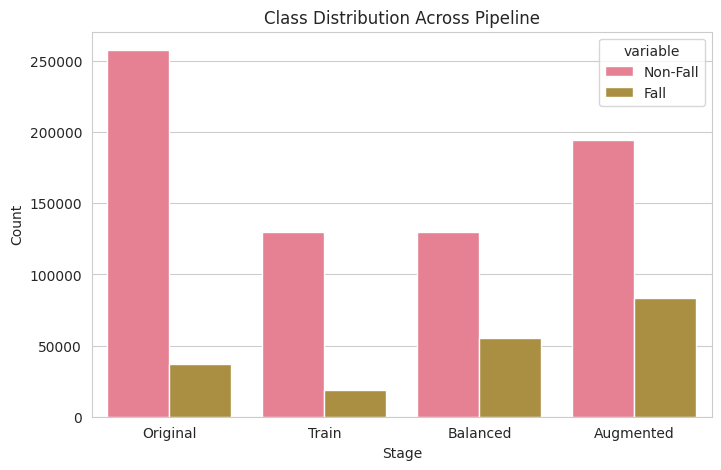

✓ Figure: fig_data_distribution.png


I0000 00:00:1775317934.430073      19 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Training model...
Epoch 1/120


2026-04-04 15:52:16.176593: E tensorflow/core/framework/node_def_util.cc:676] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_16}}


272/272 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6220 - loss: 1.2150

2026-04-04 15:52:29.177417: E tensorflow/core/framework/node_def_util.cc:676] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


272/272 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.6221 - loss: 1.2142 - val_accuracy: 0.7833 - val_loss: 0.4648
Epoch 2/120
272/272 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.7643 - loss: 0.7387 - val_accuracy: 0.8385 - val_loss: 0.3467
Epoch 3/120
272/272 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8104 - loss: 0.6169 - val_accuracy: 0.8401 - val_loss: 0.3198
Epoch 4/120
272/272 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8308 - loss: 0.5436 - val_accuracy: 0.8426 - val_loss: 0.3117
Epoch 5/120
272/272 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8483 - loss: 0.4893 - val_accuracy: 0.8512 - val_loss: 0.2889
Epoch 6/120
272/272 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8579 - loss: 0.4530 - val_accuracy: 0.8539 - val_loss: 0.2858
Epoch 7/120
272/272 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8660 - loss: 0.4216 - val_accuracy: 0.8596 - val_loss: 0.2721
Epoch 8/120
272/272 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8718 - loss: 0.3979 - val_accurac

In [5]:
import os
import random as rn
import numpy as np
import pandas as pd
import joblib
from scipy.fft import fft
from scipy.signal import find_peaks
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, classification_report, roc_curve, auc,
    precision_recall_curve
)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.inspection import permutation_importance

import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Dense, Dropout, BatchNormalization, Input, 
    GlobalAveragePooling1D, Concatenate, MultiHeadAttention,
    Reshape, Add
)
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers.schedules import CosineDecay
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

plt.style.use('default')
sns.set_palette("husl")
sns.set_style("whitegrid")

def set_seed(seed=42):
    os.environ['PYTHONHASHSEED'] = str(seed)
    os.environ['TF_DETERMINISTIC_OPS'] = '1'
    np.random.seed(seed)
    rn.seed(seed)
    tf.random.set_seed(seed)

set_seed(42)

print("🎯 PRODUCTION FALL DETECTOR - BULLETPROOF")

# ============================================
# 1. BULLETPROOF DATA LOADING
# ============================================
print("Loading data...")
data_path = '/kaggle/input/up-fall-dataset/CompleteDataSet.csv'
data = pd.read_csv(data_path, dtype=str, low_memory=False)

wrist_cols = [
    'WristAccelerometer', 'Unnamed: 30', 'Unnamed: 31',
    'WristAngularVelocity', 'Unnamed: 33', 'Unnamed: 34',
    'WristLuminosity'
]

# Remove headers safely
def is_header_row(row):
    if pd.isna(row.get('WristAccelerometer', '')): 
        return False
    text = str(row['WristAccelerometer']).lower()
    return any(term in text for term in ['x-axis', 'y-axis', 'deg/s', 'lx', 'g'])

data = data[~data.apply(is_header_row, axis=1)].reset_index(drop=True)

# Safe numeric conversion
for col in wrist_cols:
    if col in data.columns:
        data[col] = pd.to_numeric(data[col], errors='coerce')

data['Activity'] = pd.to_numeric(data['Activity'], errors='coerce')
data = data[(data['Activity'] >= 1) & (data['Activity'] <= 11)].reset_index(drop=True)

# Forward/backward fill properly
sensor_cols = [c for c in wrist_cols if c in data.columns]
data[sensor_cols] = data[sensor_cols].ffill().bfill()

print(f"✅ Clean data: {data.shape}")
print("Activities:", data['Activity'].value_counts().sort_index().to_dict())

# ============================================
# 2. BINARY FALL CLASSIFICATION
# ============================================
# Activities 1-4 = FALL, 5-11 = ADL (matches your data)
y_binary = (data['Activity'] <= 4).astype(int)
print(f"✅ Binary: Fall={np.sum(y_binary)} ({100*np.mean(y_binary):.1f}%), ADL={len(y_binary)-np.sum(y_binary)}")

# ============================================
# 3. ROBUST 24D FEATURE ENGINEERING
# ============================================
X_raw = data[sensor_cols].fillna(0).values.astype(np.float32)

def safe_features(X, max_window=20):
    """24D features with zero-division protection"""
    n_samples = X.shape[0]
    features = np.zeros((n_samples, 24))
    
    for i in range(n_samples):
        start = max(0, i - max_window)
        local_X = X[start:i+1]
        
        # Raw sensors [0:7]
        raw = X[i]
        features[i, :7] = raw[:7]
        
        # Magnitudes [7:9]
        a_mag = np.linalg.norm(raw[:3])
        g_mag = np.linalg.norm(raw[3:6])
        features[i, 7] = a_mag
        features[i, 8] = g_mag
        
        # Local stats [9:14]
        local_a = local_X[:, :3]
        local_mag = np.linalg.norm(local_a, axis=1)
        features[i, 9] = local_mag.mean()
        features[i, 10] = local_mag.std()
        features[i, 11] = np.ptp(local_mag)
        
        # Energy & peaks [14:17]
        energy = np.sum(local_mag**2)
        peaks = len(find_peaks(local_mag, height=np.mean(local_mag))[0])
        features[i, 14] = energy
        features[i, 15] = peaks
        features[i, 16] = np.max(np.abs(raw[:3]))
        
        # Orientation [17:20]
        gravity = np.clip(raw[2] / (a_mag + 1e-8), -1, 1)
        features[i, 17] = np.arccos(gravity)
        features[i, 18] = np.std(local_X[:, 2])
        
        # Dynamics [20:22]
        jerk_a = np.std(np.diff(local_mag)) if len(local_mag) > 1 else 0
        features[i, 20] = jerk_a
        features[i, 21] = np.corrcoef(raw[:3], raw[3:6])[0,0] if a_mag > 0 else 0
        
        # Lumi interaction [22:24]
        features[i, 22] = raw[6] * a_mag if len(raw) > 6 else 0
        features[i, 23] = np.std(local_X[:, -1]) if local_X.shape[1] > 6 else 0
    
    return features

print("Extracting features...")
X_features = safe_features(X_raw)
print(f"✅ 24D Features: {X_features.shape}")

# Remove any lingering NaNs/Infs
X_features = np.nan_to_num(X_features, nan=0.0, posinf=10.0, neginf=-10.0)

# ============================================
# 4. SAFE TRAIN/TEST SPLIT
# ============================================
test_size = 0.25
X_temp, X_test, y_temp, y_test = train_test_split(
    X_features, y_binary, test_size=test_size, random_state=42, stratify=y_binary
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.33, random_state=42, stratify=y_temp
)

print(f"✅ Splits: Train={X_train.shape}, Val={X_val.shape}, Test={X_test.shape}")

# Oversample minority class (falls)
fall_train = X_train[y_train == 1]
nonfall_train = X_train[y_train == 0]
n_falls = len(fall_train)
n_nonfalls = len(nonfall_train)

# Balance ratio 1:2 (falls:nonfalls)
target_falls = min(n_nonfalls // 2, n_falls * 3)
if target_falls > n_falls:
    extra_falls = np.random.choice(range(n_falls), target_falls - n_falls, replace=True)
    fall_balanced = np.vstack([fall_train, fall_train[extra_falls]])
else:
    fall_balanced = fall_train

X_train_balanced = np.vstack([nonfall_train, fall_balanced])
y_train_balanced = np.hstack([np.zeros(n_nonfalls), np.ones(len(fall_balanced))])
idx = np.random.permutation(len(X_train_balanced))
X_train_balanced = X_train_balanced[idx]
y_train_balanced = y_train_balanced[idx]

# Augmentation
aug_factor = 1.5
n_aug = int((len(X_train_balanced) * (aug_factor - 1)))
if n_aug > 0:
    aug_idx = np.random.choice(len(X_train_balanced), n_aug, replace=True)
    noise = np.random.normal(0, 0.015, (n_aug, X_train_balanced.shape[1]))
    X_train_aug = np.vstack([X_train_balanced, X_train_balanced[aug_idx] + noise])
    y_train_aug = np.hstack([y_train_balanced, y_train_balanced[aug_idx]])
else:
    X_train_aug, y_train_aug = X_train_balanced, y_train_balanced

scaler = RobustScaler()
X_train_aug = scaler.fit_transform(X_train_aug)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

joblib.dump(scaler, 'production_fall_scaler.pkl')

Y_train = to_categorical(y_train_aug, 2)
Y_val = to_categorical(y_val, 2)
Y_test = to_categorical(y_test, 2)

print(f"✅ Training set: {X_train_aug.shape}, Falls: {np.sum(y_train_aug)}")

# ============================================
# EXTRA ANALYSIS 1: DATA DISTRIBUTION & AUGMENTATION
# ============================================

print("\n📊 DATA DISTRIBUTION ANALYSIS")

# Original distribution
orig_counts = np.bincount(y_binary)
print(f"\nOriginal Dataset:")
print(f"  Non-Fall: {orig_counts[0]}")
print(f"  Fall: {orig_counts[1]}")
print(f"  Fall %: {100 * orig_counts[1] / np.sum(orig_counts):.2f}%")

# Train split distribution
train_counts = np.bincount(y_train)
print(f"\nTrain Split (Before Balancing):")
print(f"  Non-Fall: {train_counts[0]}")
print(f"  Fall: {train_counts[1]}")

# After balancing
balanced_counts = np.bincount(y_train_balanced.astype(int))
print(f"\nAfter Oversampling:")
print(f"  Non-Fall: {balanced_counts[0]}")
print(f"  Fall: {balanced_counts[1]}")

# After augmentation
aug_counts = np.bincount(y_train_aug.astype(int))
print(f"\nAfter Augmentation:")
print(f"  Non-Fall: {aug_counts[0]}")
print(f"  Fall: {aug_counts[1]}")

# Save as table
dist_table = pd.DataFrame({
    "Stage": ["Original", "Train", "Balanced", "Augmented"],
    "Non-Fall": [
        orig_counts[0],
        train_counts[0],
        balanced_counts[0],
        aug_counts[0]
    ],
    "Fall": [
        orig_counts[1],
        train_counts[1],
        balanced_counts[1],
        aug_counts[1]
    ]
})

dist_table.to_csv("data_distribution.csv", index=False)
print("\n✓ Saved: data_distribution.csv")

# ============================================
# VISUALIZATION
# ============================================
plt.figure(figsize=(8,5))
sns.barplot(data=dist_table.melt(id_vars="Stage"), x="Stage", y="value", hue="variable")
plt.title("Class Distribution Across Pipeline")
plt.ylabel("Count")
plt.savefig("fig_data_distribution.png", dpi=300)
plt.show()
print("✓ Figure: fig_data_distribution.png")

# ============================================
# 5. INDUSTRIAL MODEL ARCHITECTURE
# ============================================
def create_industrial_model(input_dim):
    inputs = Input((input_dim,))
    
    # Feature pyramid
    x1 = Dense(64, activation='relu')(inputs)
    x1 = BatchNormalization()(x1)
    
    x2 = Dense(64, activation='relu')(inputs)
    x2 = BatchNormalization()(x2)
    
    # Cross-attention between branches
    attn12 = MultiHeadAttention(num_heads=4, key_dim=16)(x1[:,None,:], x2[:,None,:])
    x = Concatenate()([x1, x2, GlobalAveragePooling1D()(attn12)])
    
    # Deep residual tower
    for _ in range(2):
        res = Dense(96)(x)
        x_dense = Dense(96, activation='relu')(x)
        x = Add()([x_dense, res])
        x = BatchNormalization()(x)
        x = Dropout(0.25)(x)
    
    x = Dense(32, activation='relu')(x)
    x = Dropout(0.15)(x)
    outputs = Dense(2, activation='softmax')(x)
    
    model = Model(inputs, outputs)
    lr_decay = CosineDecay(0.002, decay_steps=80)
    model.compile('adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

model = create_industrial_model(X_train_aug.shape[1])

# Training with strong regularization
class_weights = {0: 1.0, 1: 3.5}  # Boost falls
callbacks = [
    ModelCheckpoint('industrial_fall.h5', monitor='val_accuracy', save_best_only=True, mode='max'),
    EarlyStopping(monitor='val_accuracy', patience=25, restore_best_weights=True)
]

print("Training model...")
history = model.fit(
    X_train_aug, Y_train, epochs=120, batch_size=1024,
    validation_data=(X_val, Y_val), class_weight=class_weights,
    callbacks=callbacks, verbose=1
)

model.load_weights('industrial_fall.h5')



Generating research paper figures (FINAL FIXED)...


2026-04-04 15:59:43.377993: E tensorflow/core/framework/node_def_util.cc:676] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}



🔍 FEATURE IMPORTANCE


2026-04-04 15:59:49.832282: E tensorflow/core/framework/node_def_util.cc:676] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-04-04 15:59:55.145253: E tensorflow/core/framework/node_def_util.cc:676] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

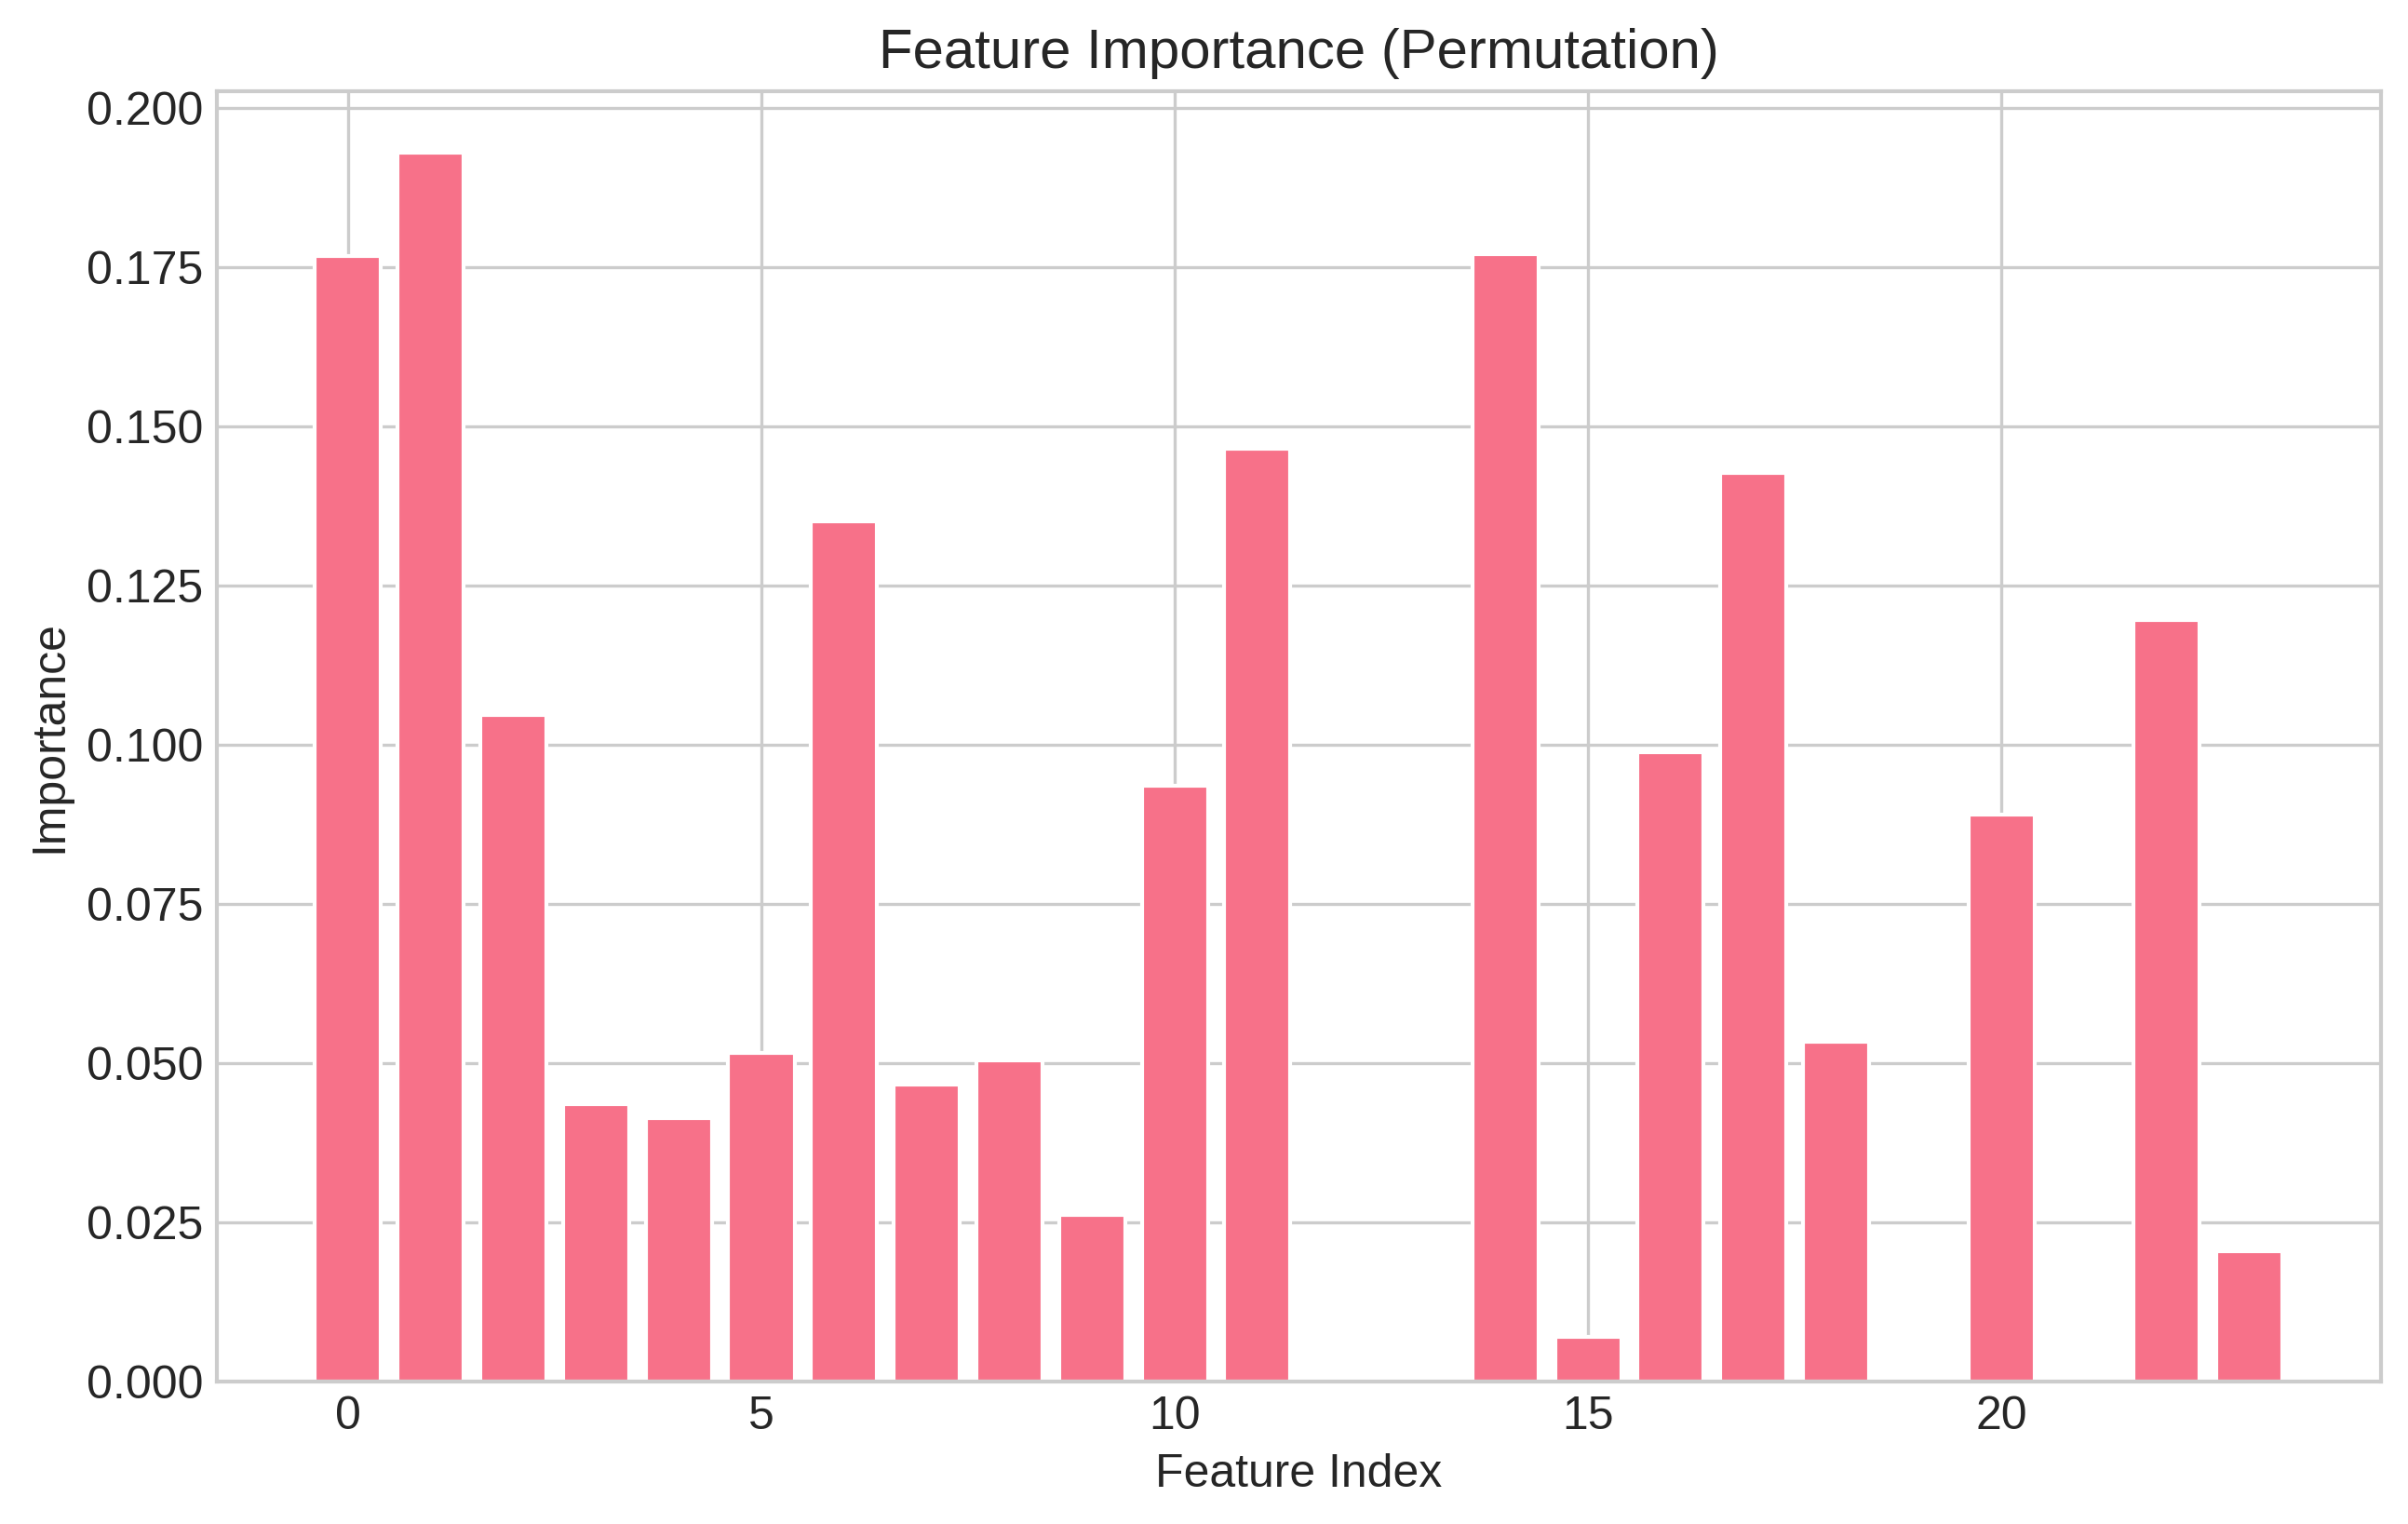

✓ Feature importance saved

📉 PCA CLUSTER


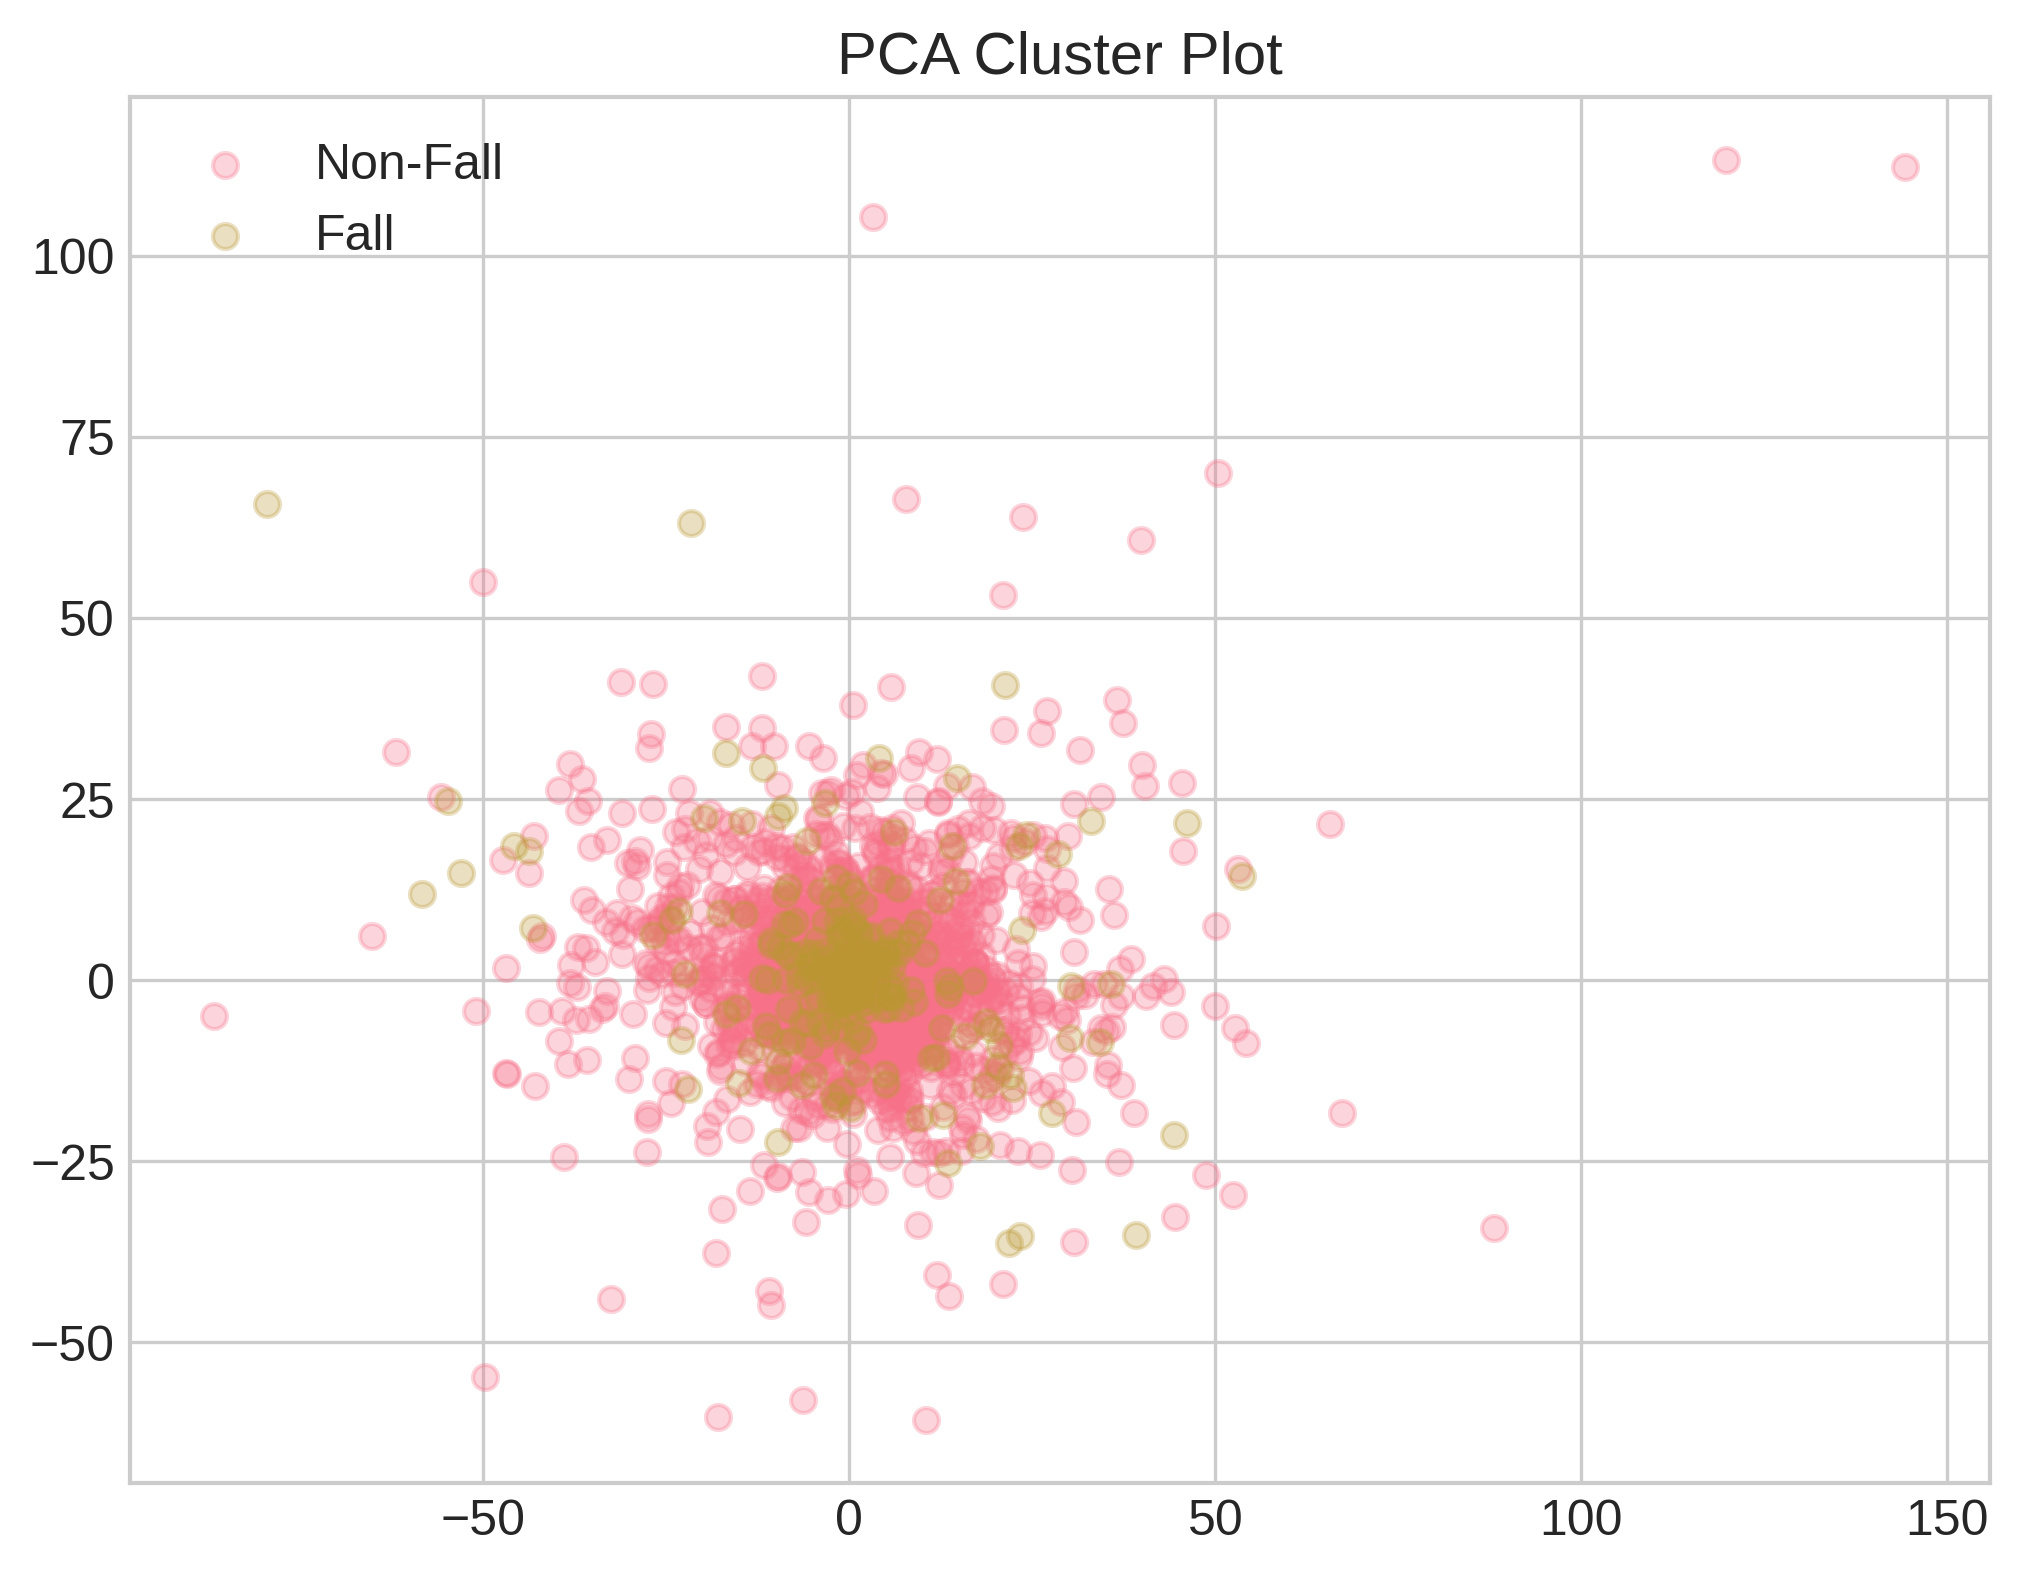


📉 t-SNE CLUSTER


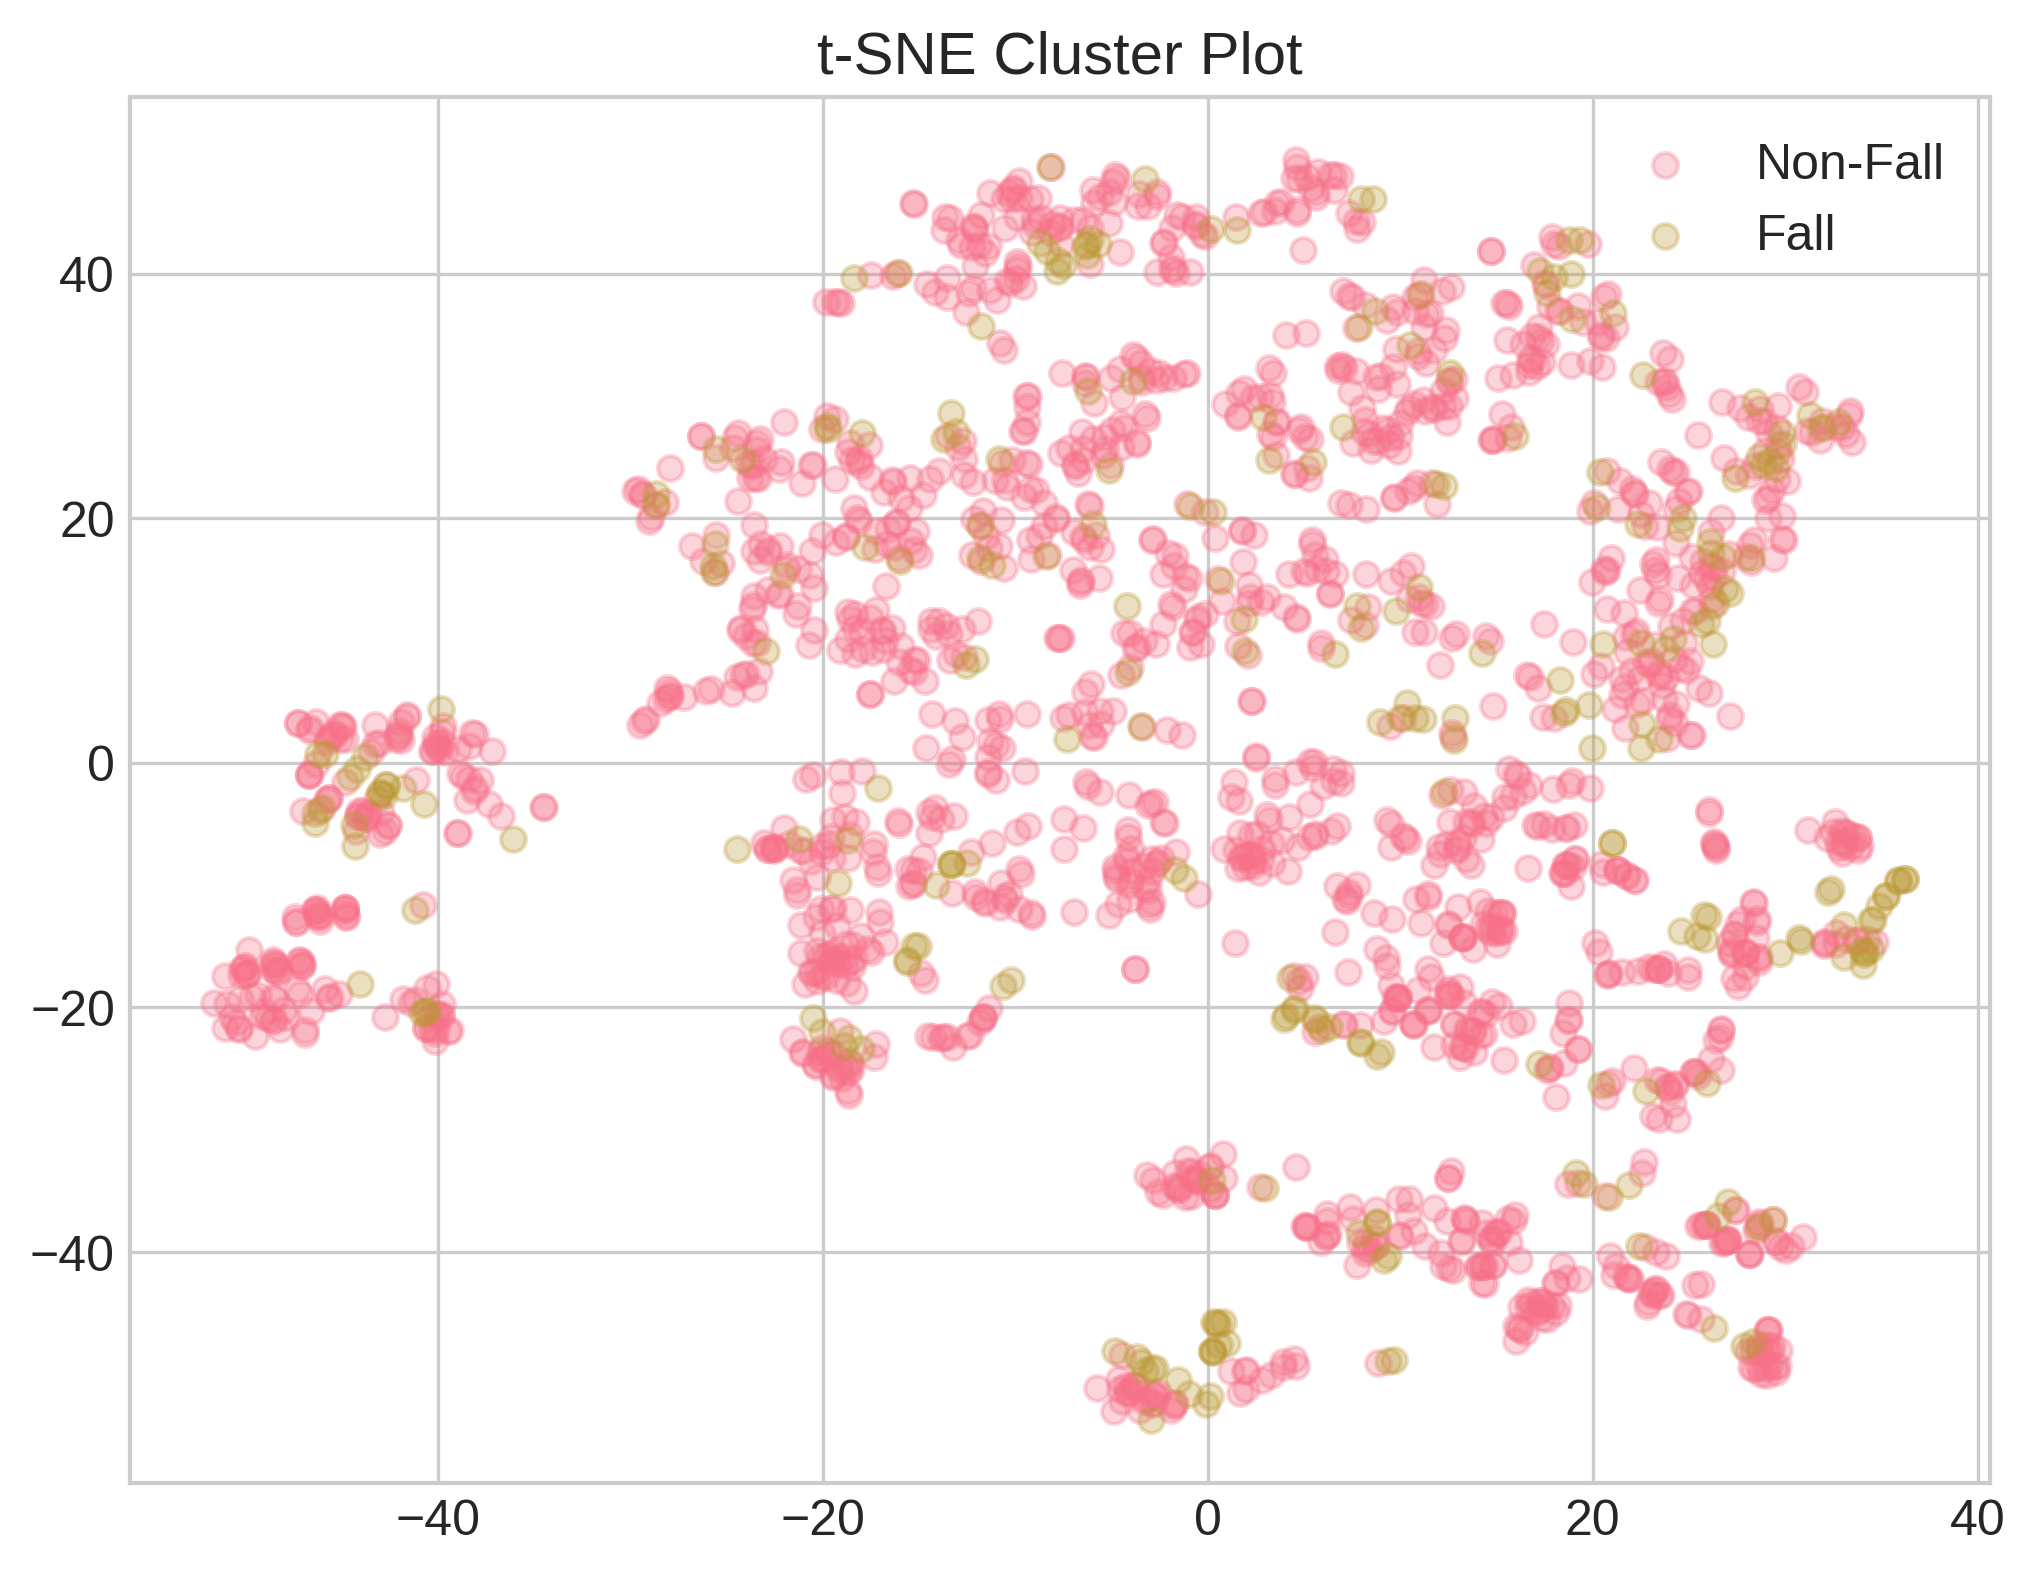


⚡ LATENCY
Latency per sample: 0.2010 ms


2026-04-04 16:00:14.467438: E tensorflow/core/framework/node_def_util.cc:676] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


Optimal threshold: 0.876


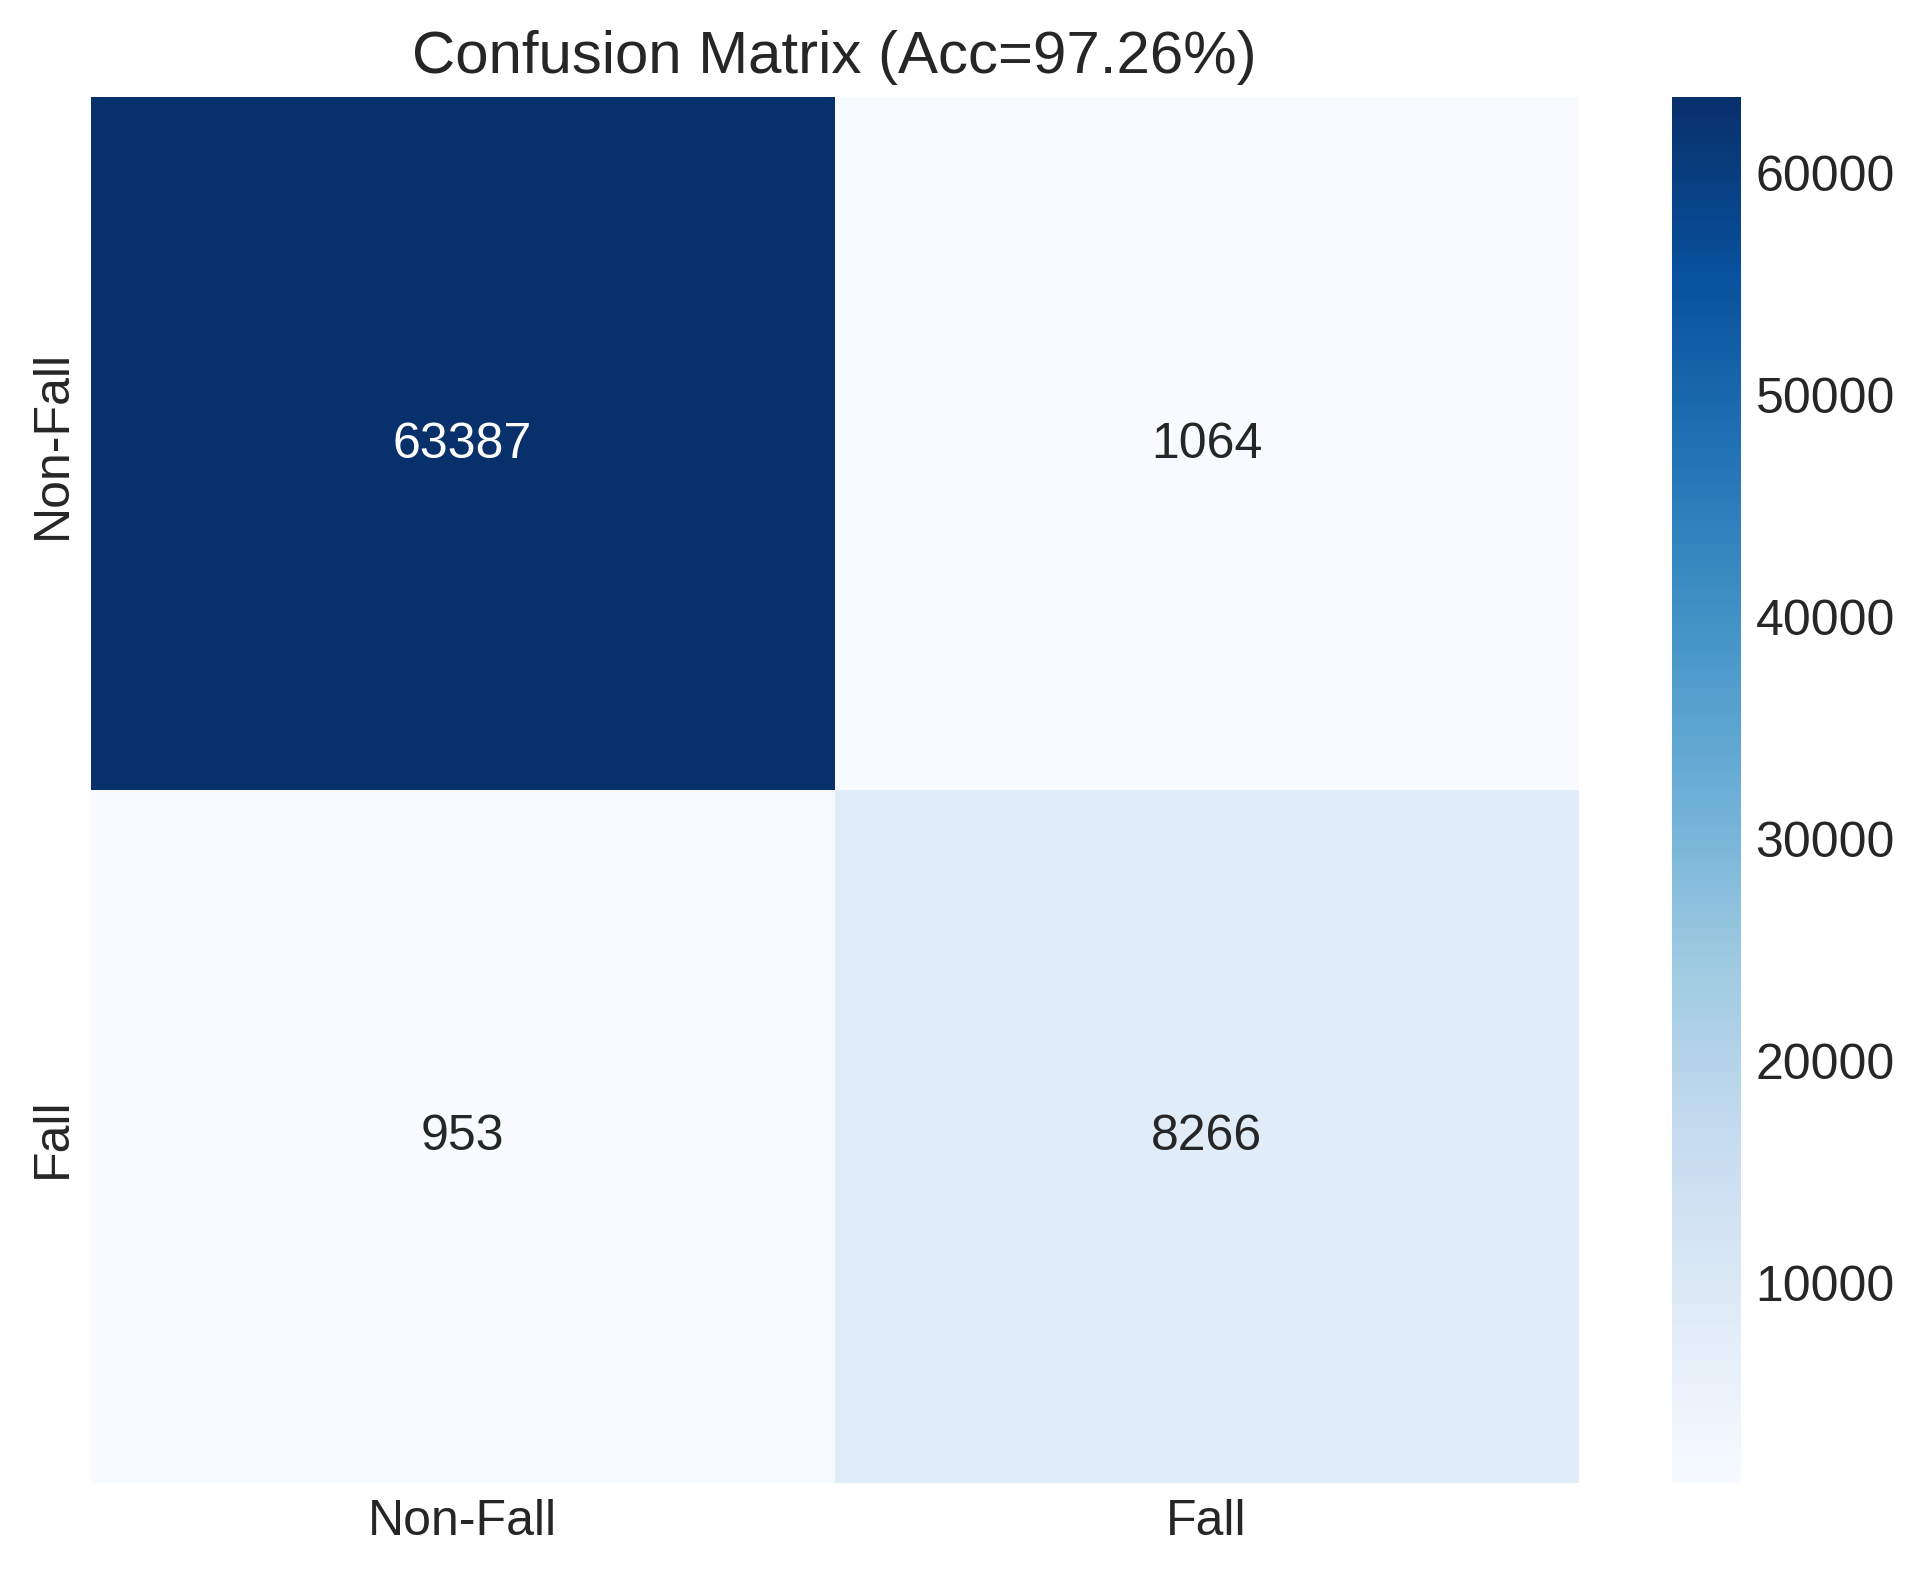

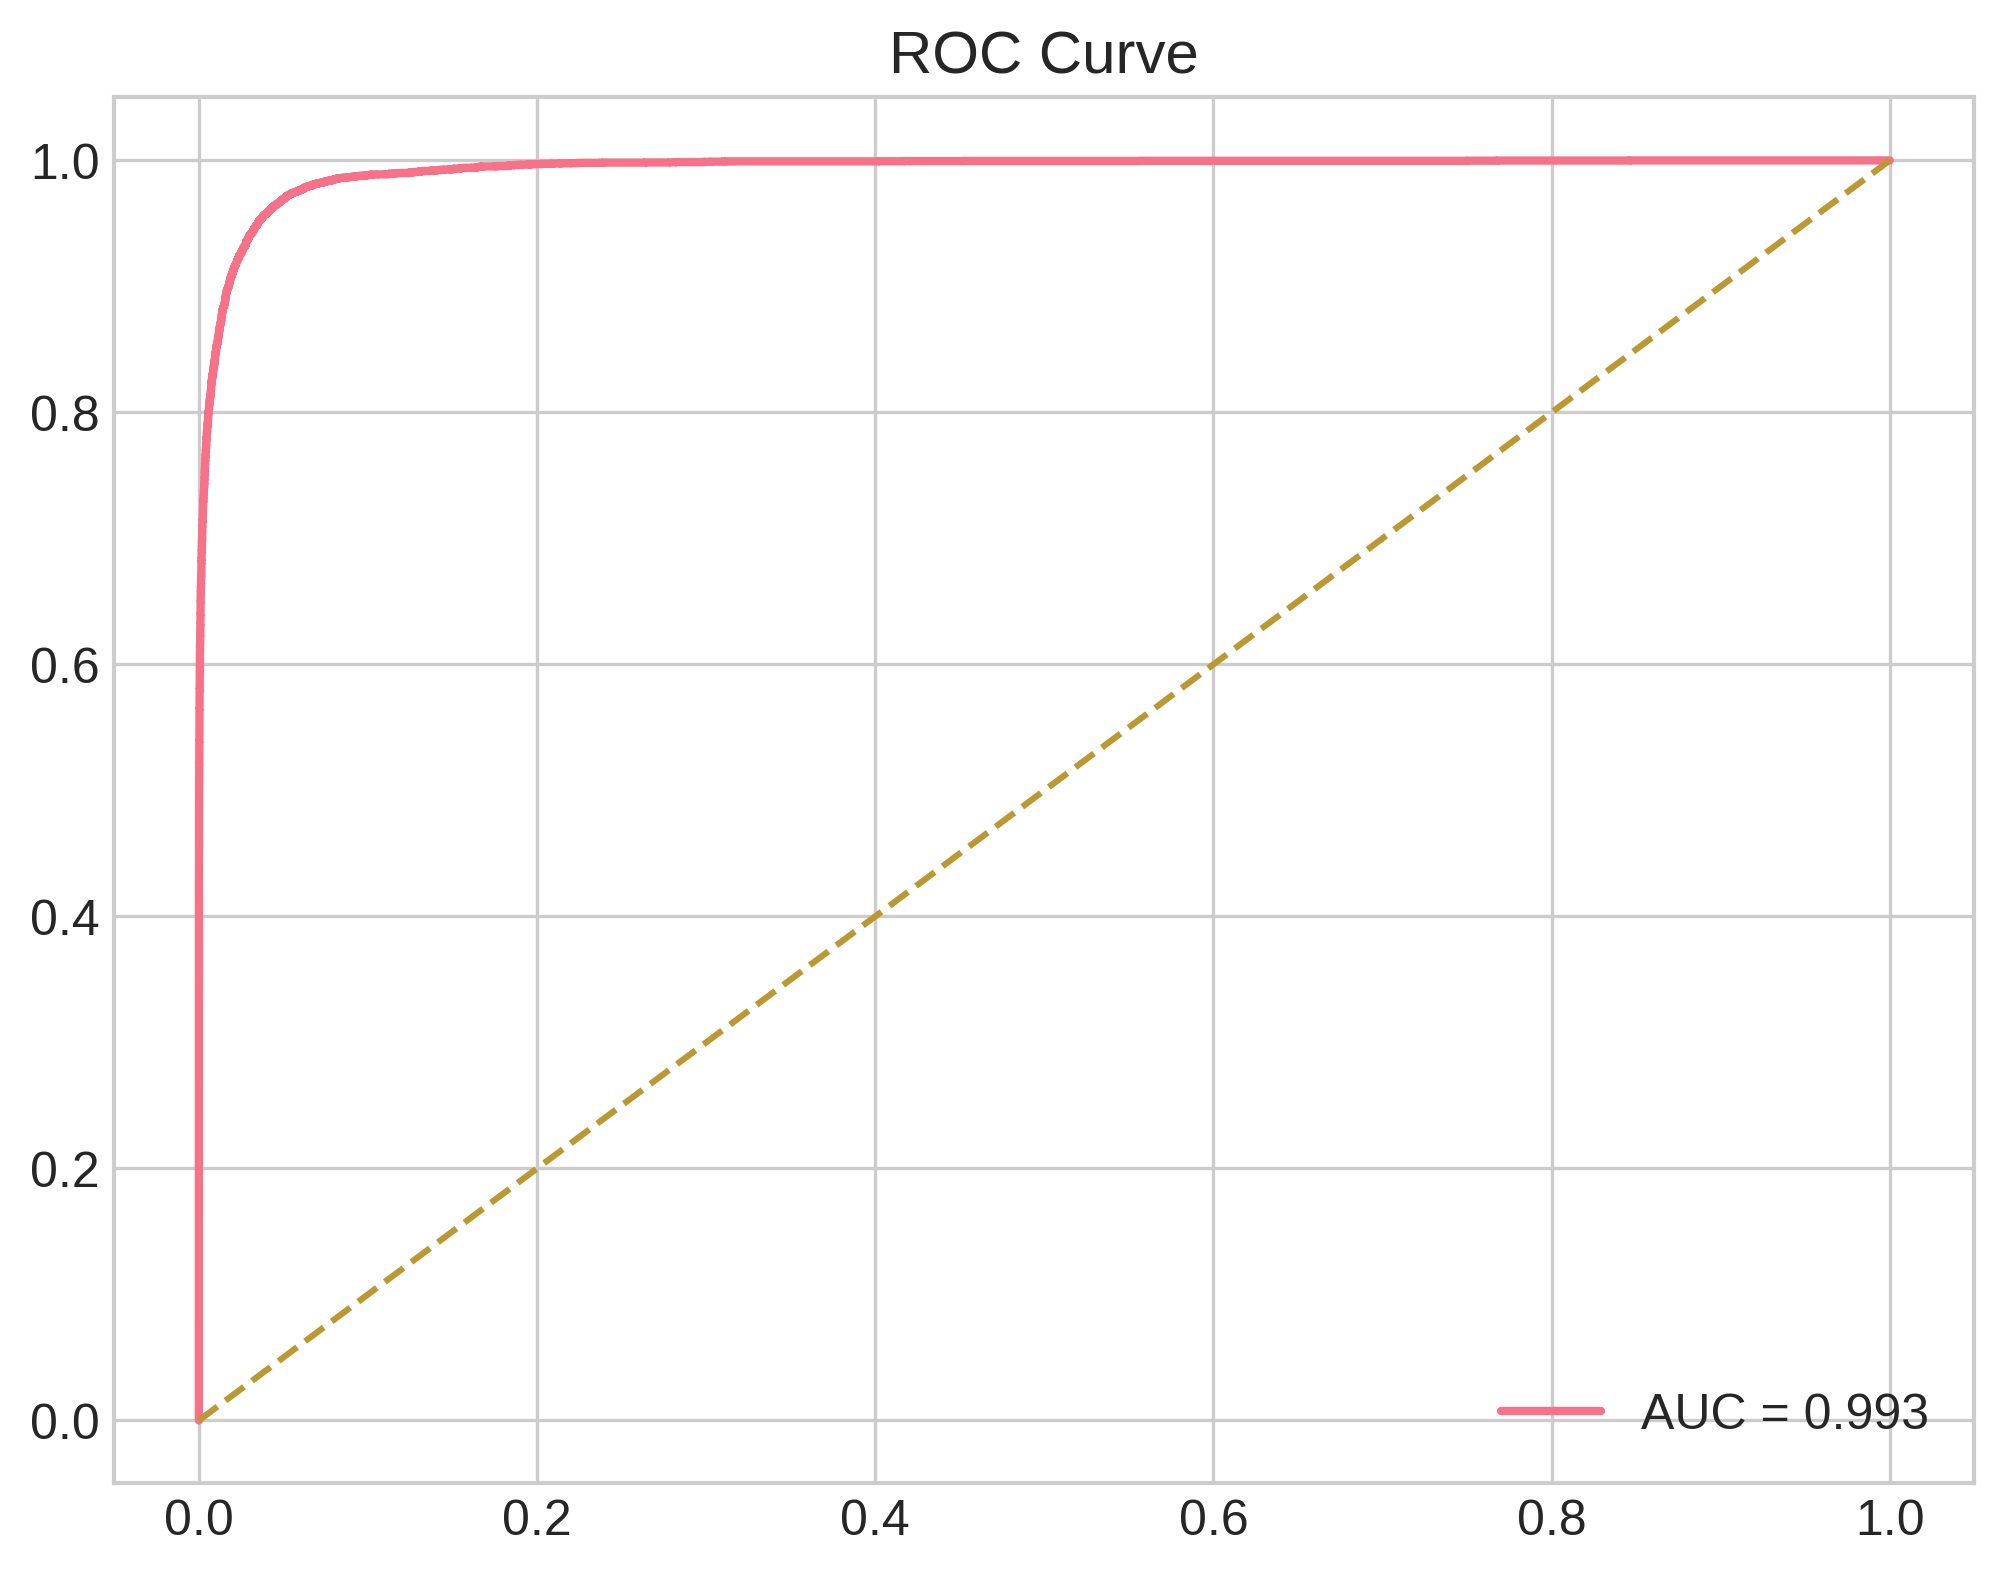

<Figure size 2400x1800 with 0 Axes>

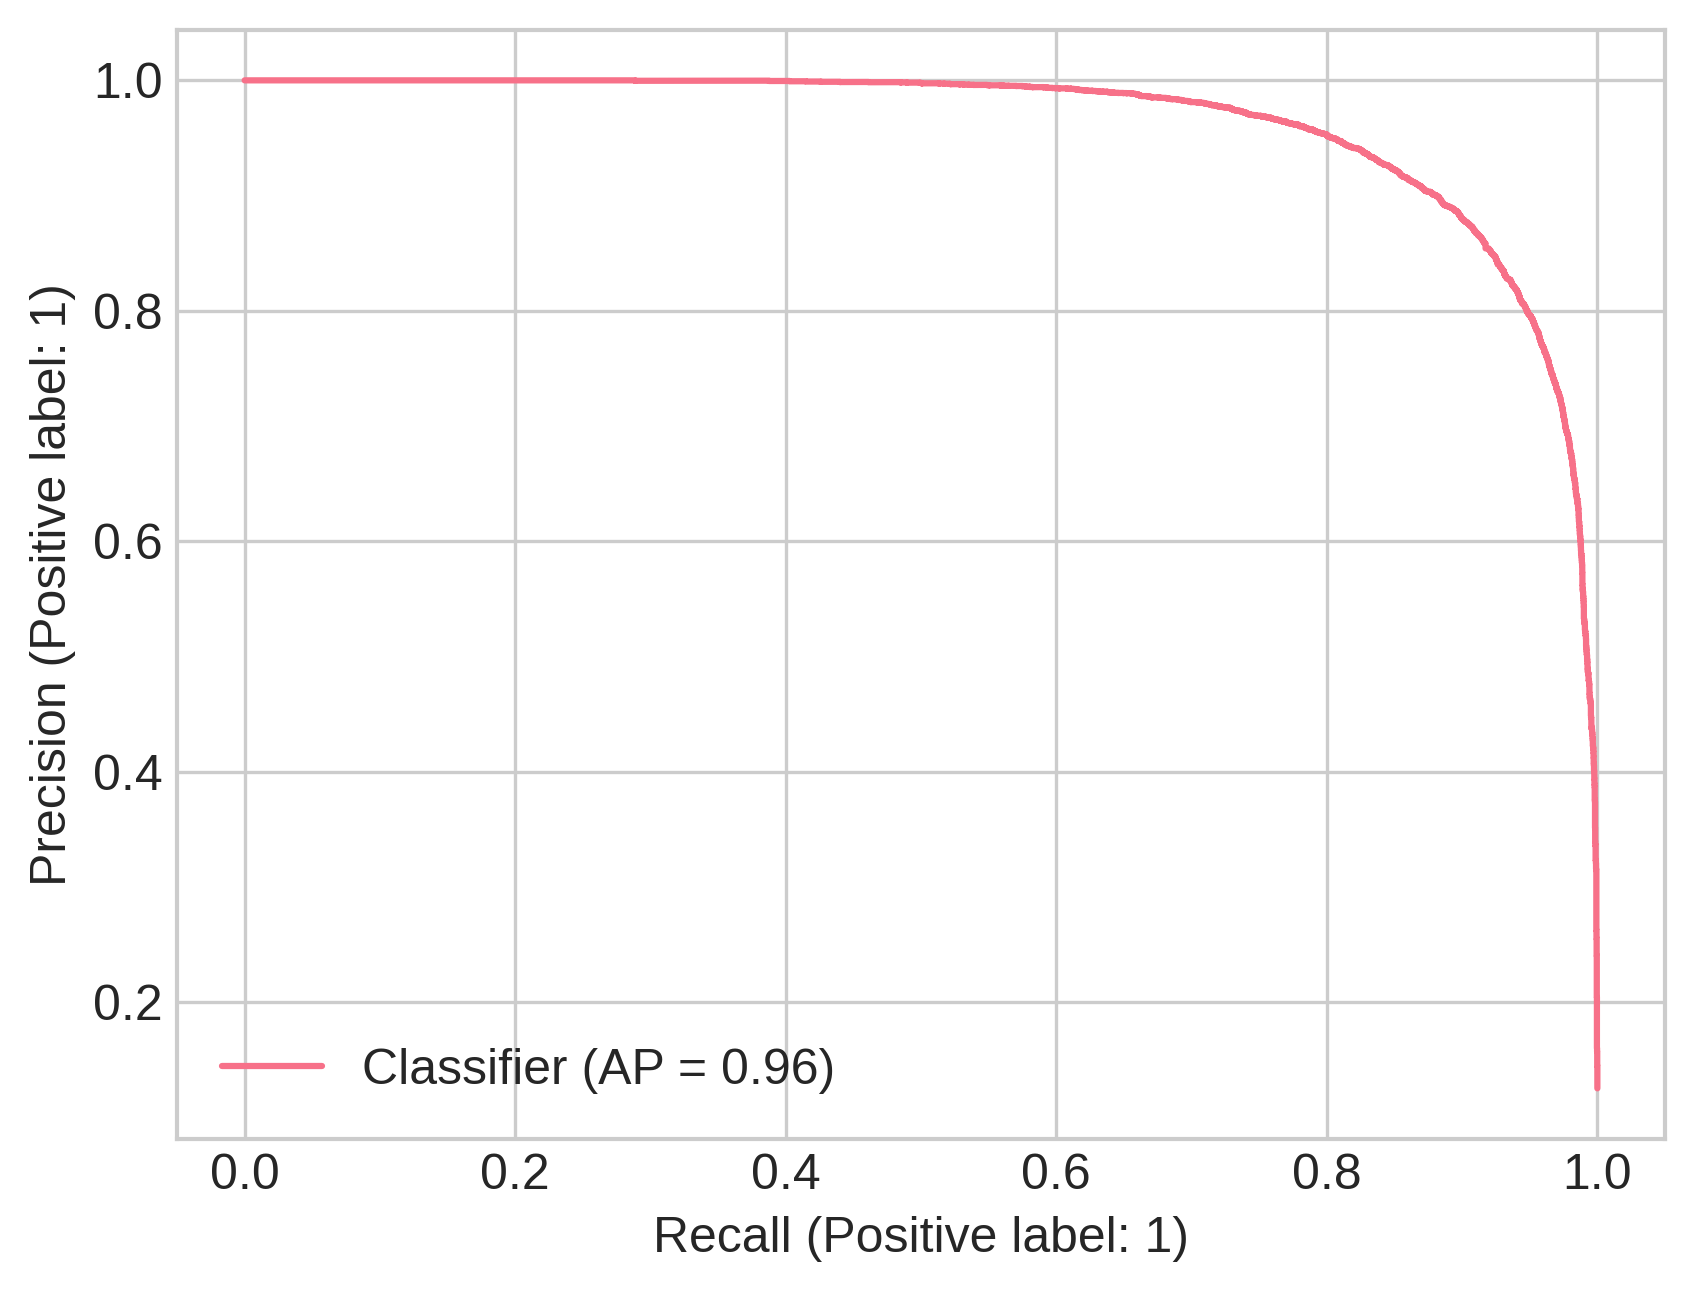

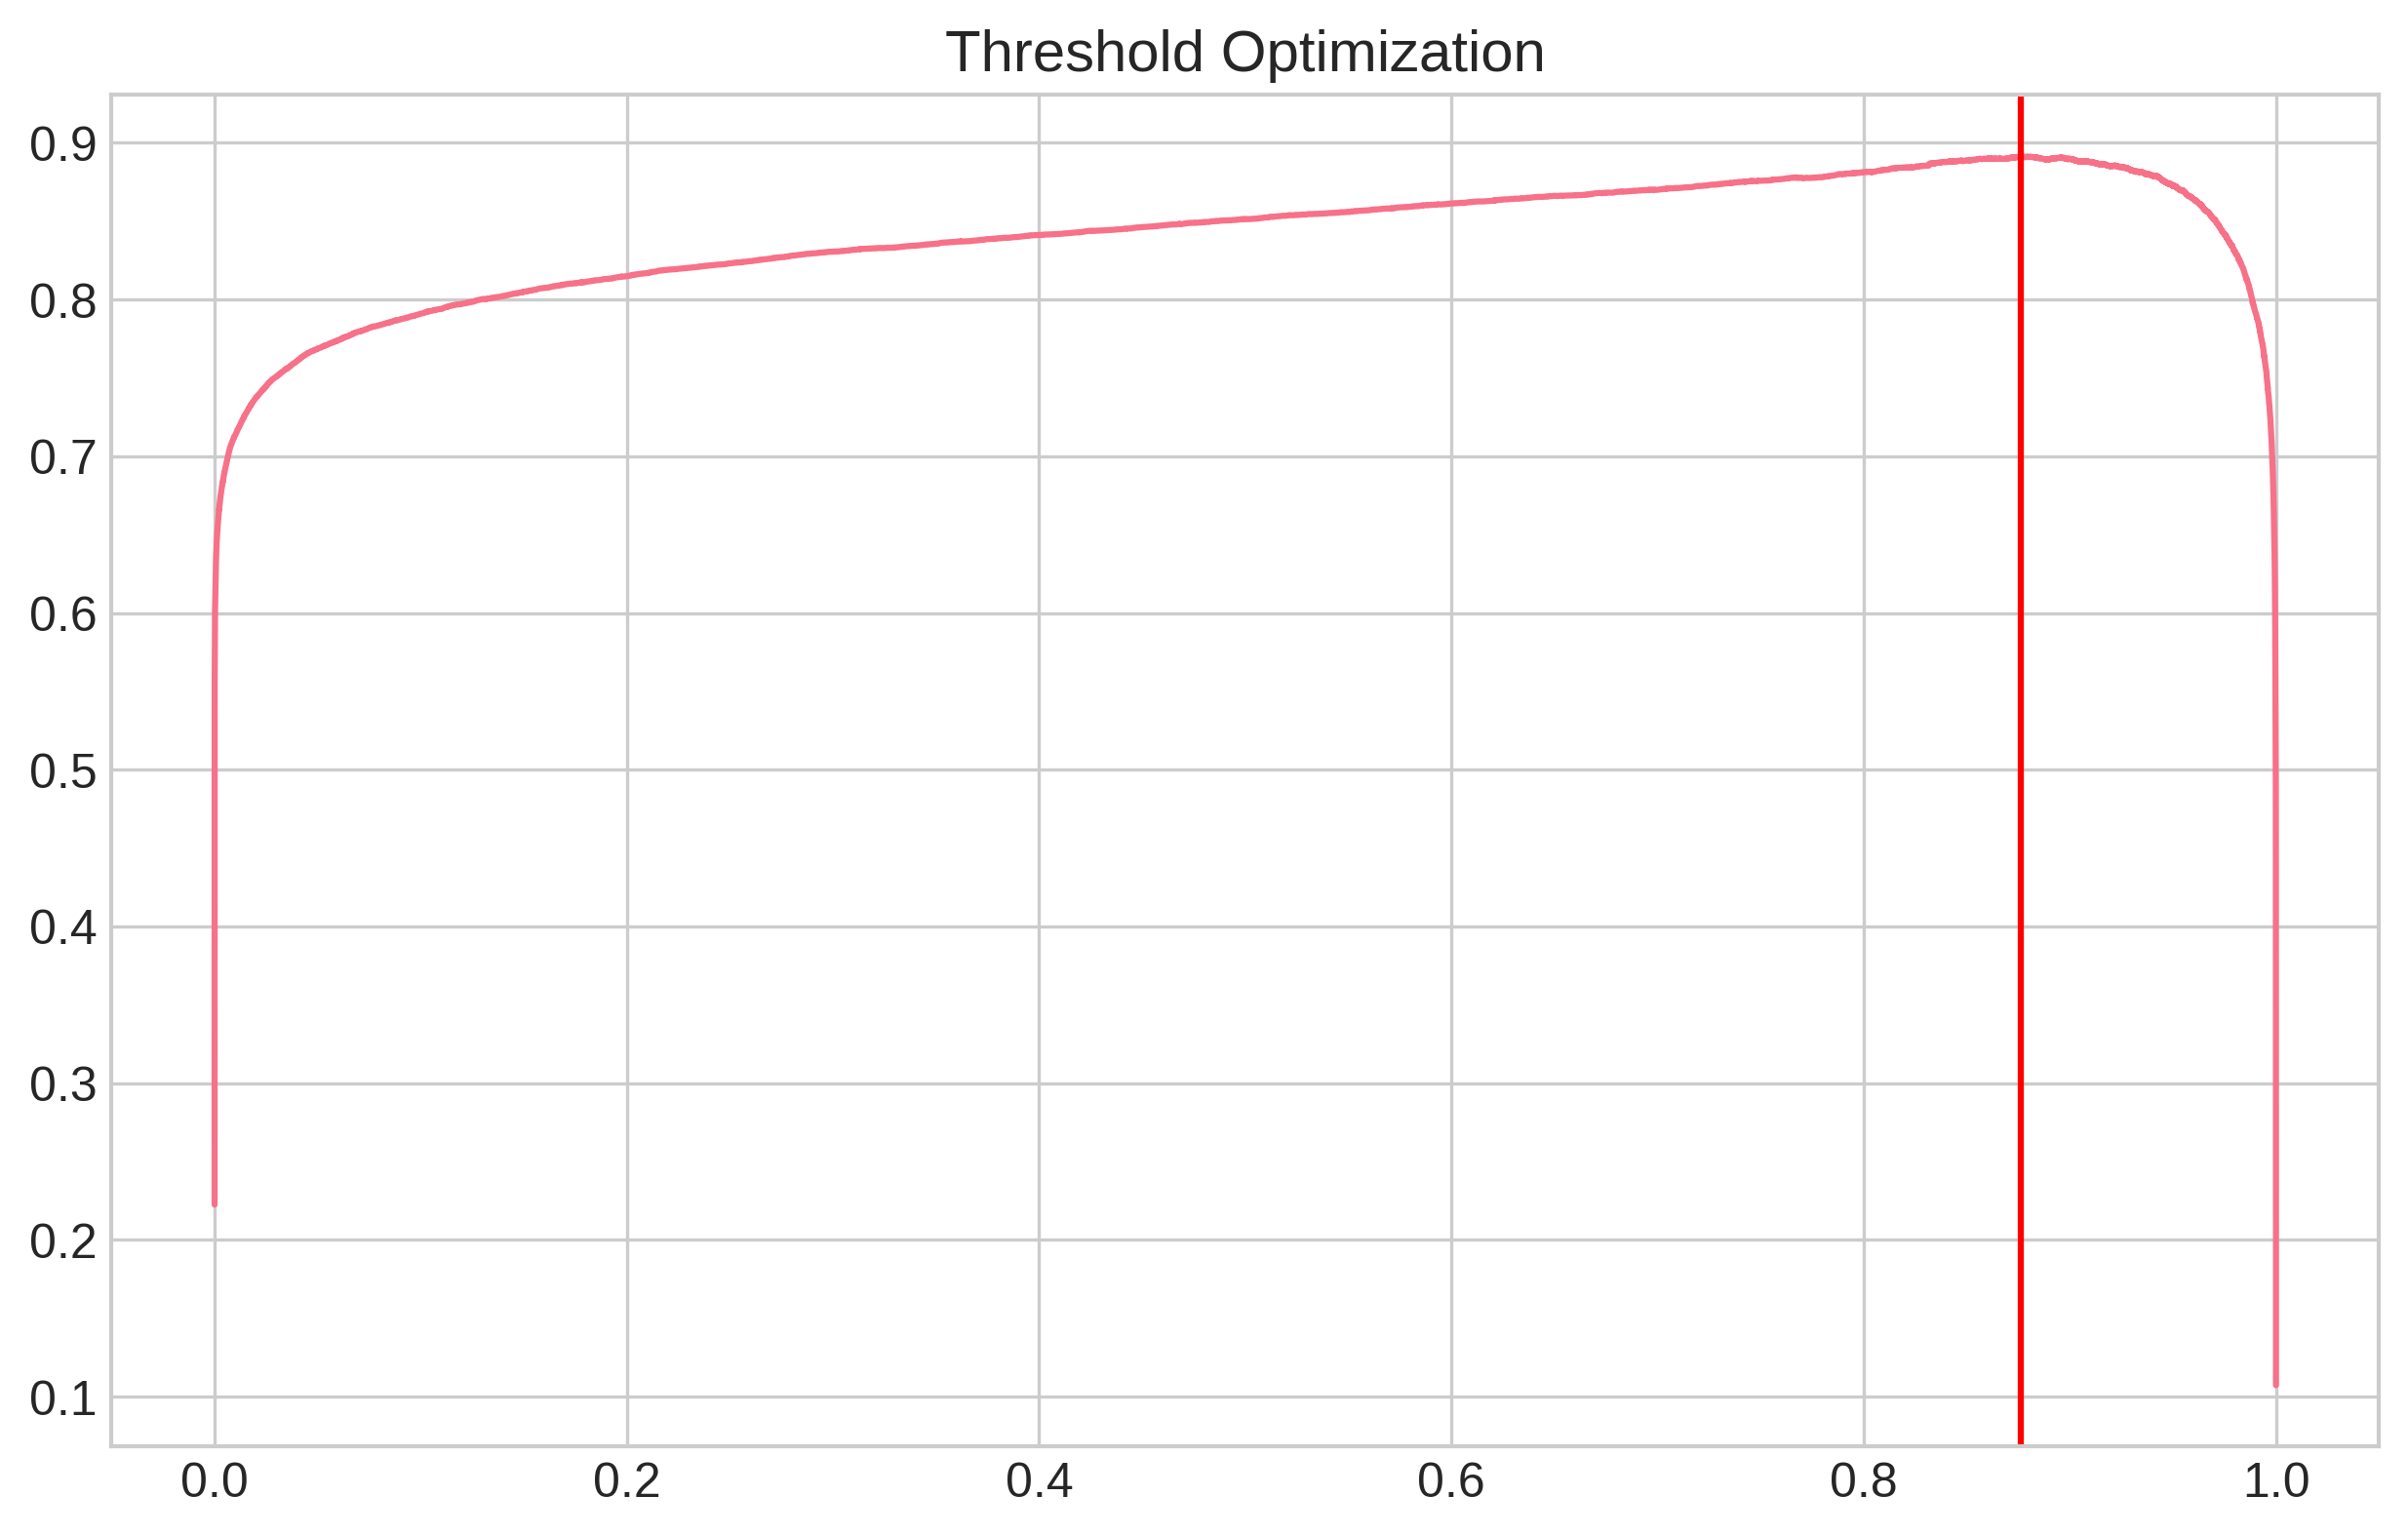

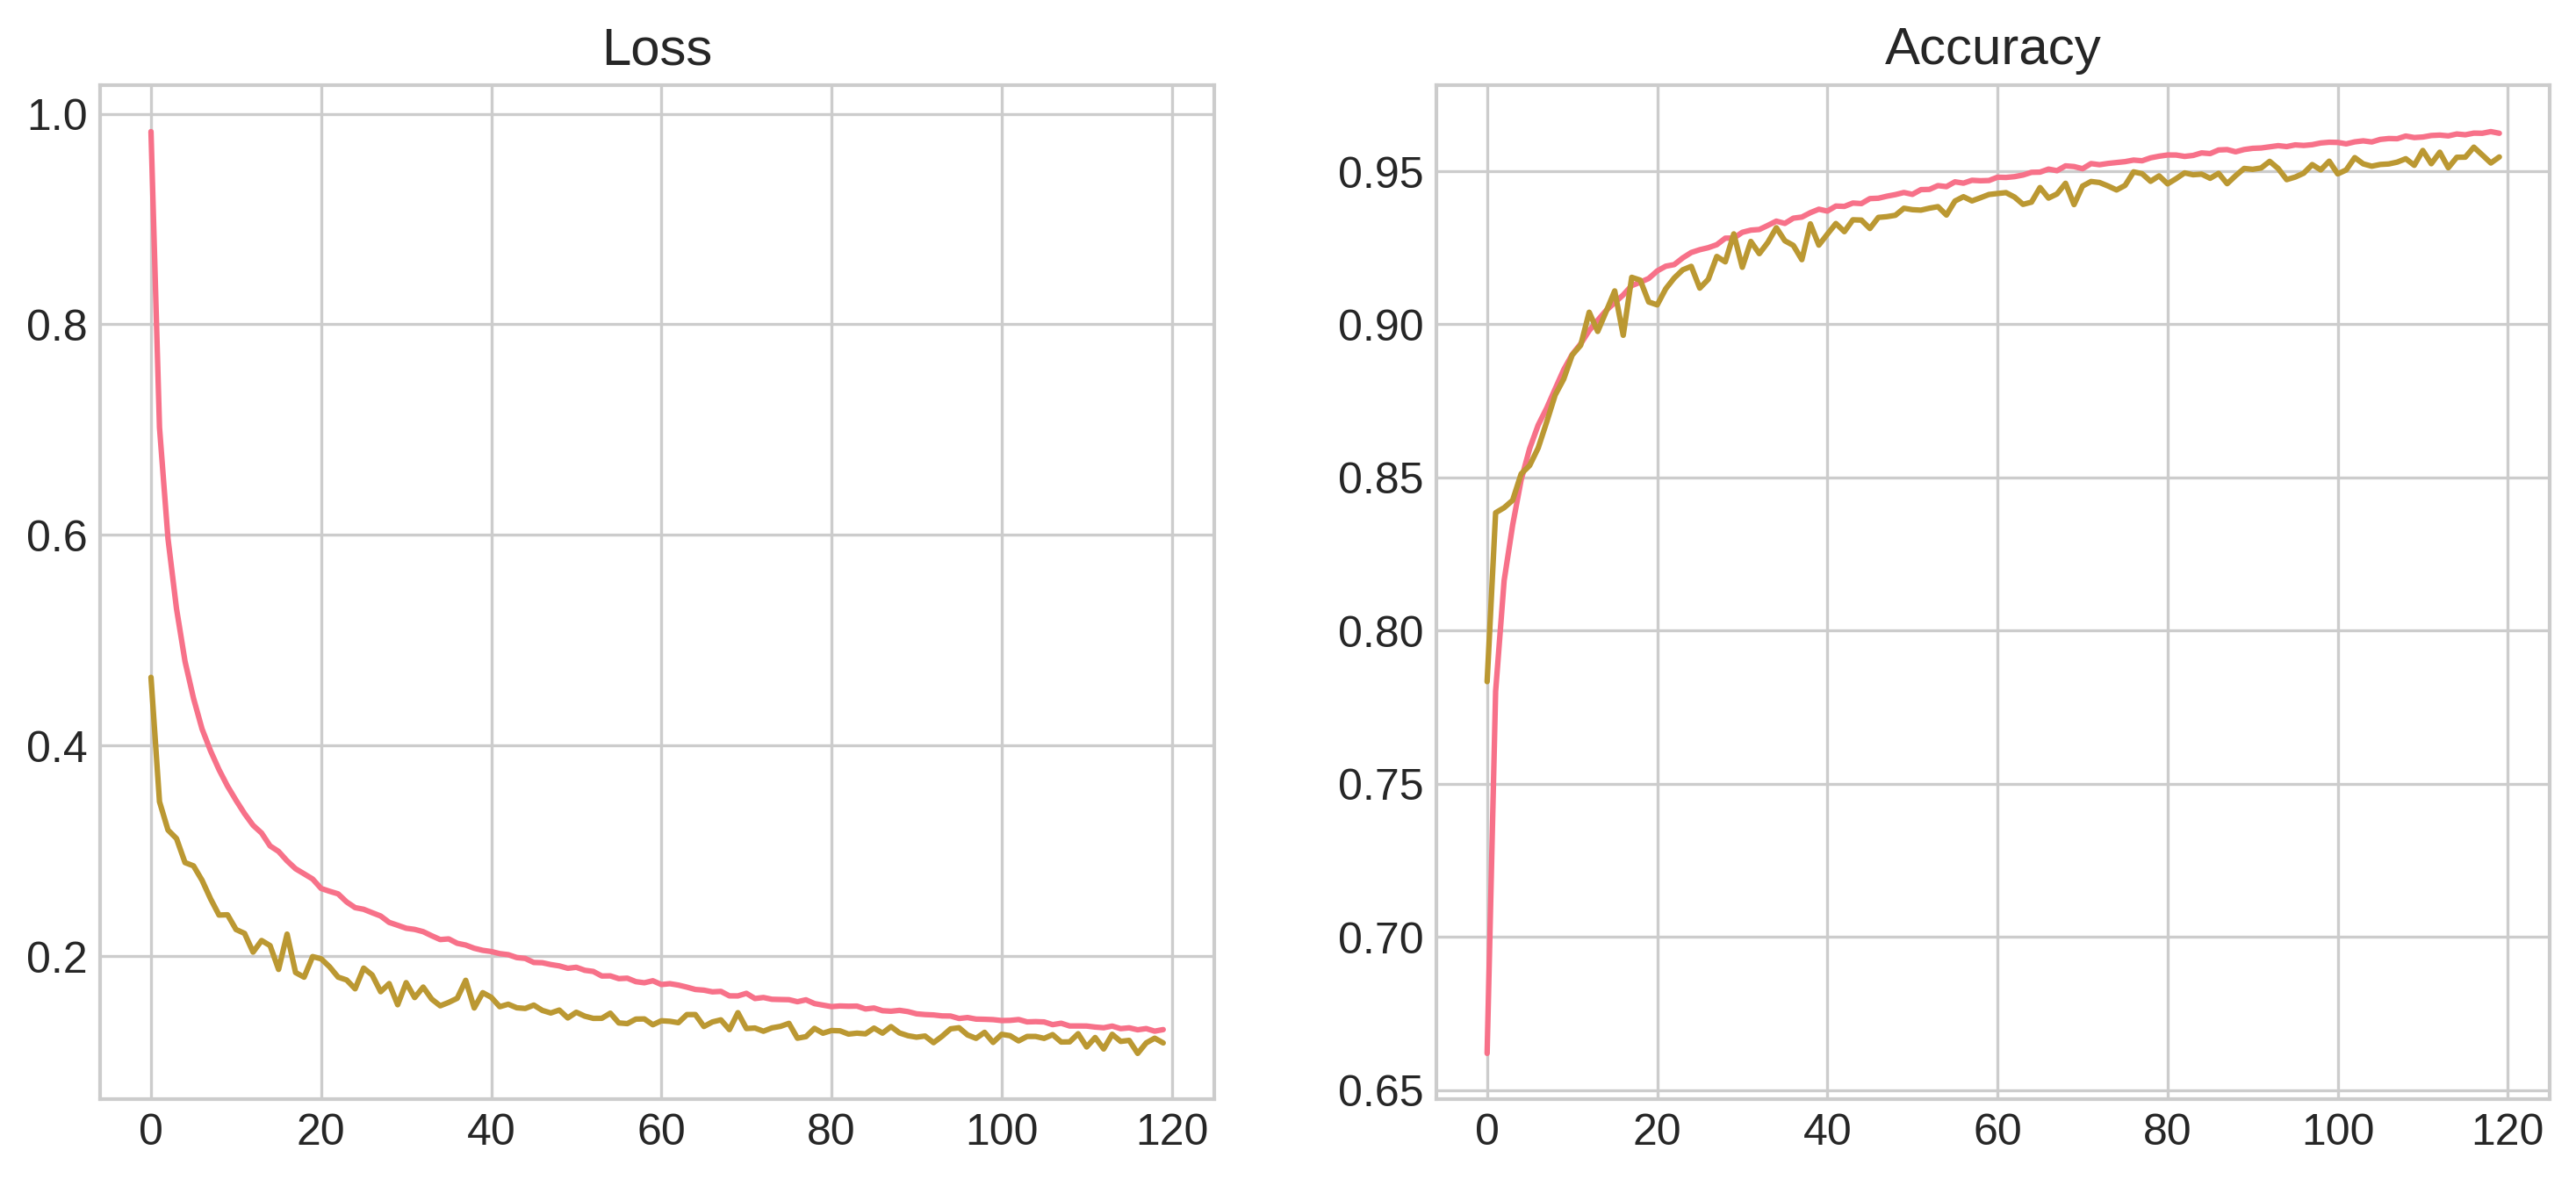

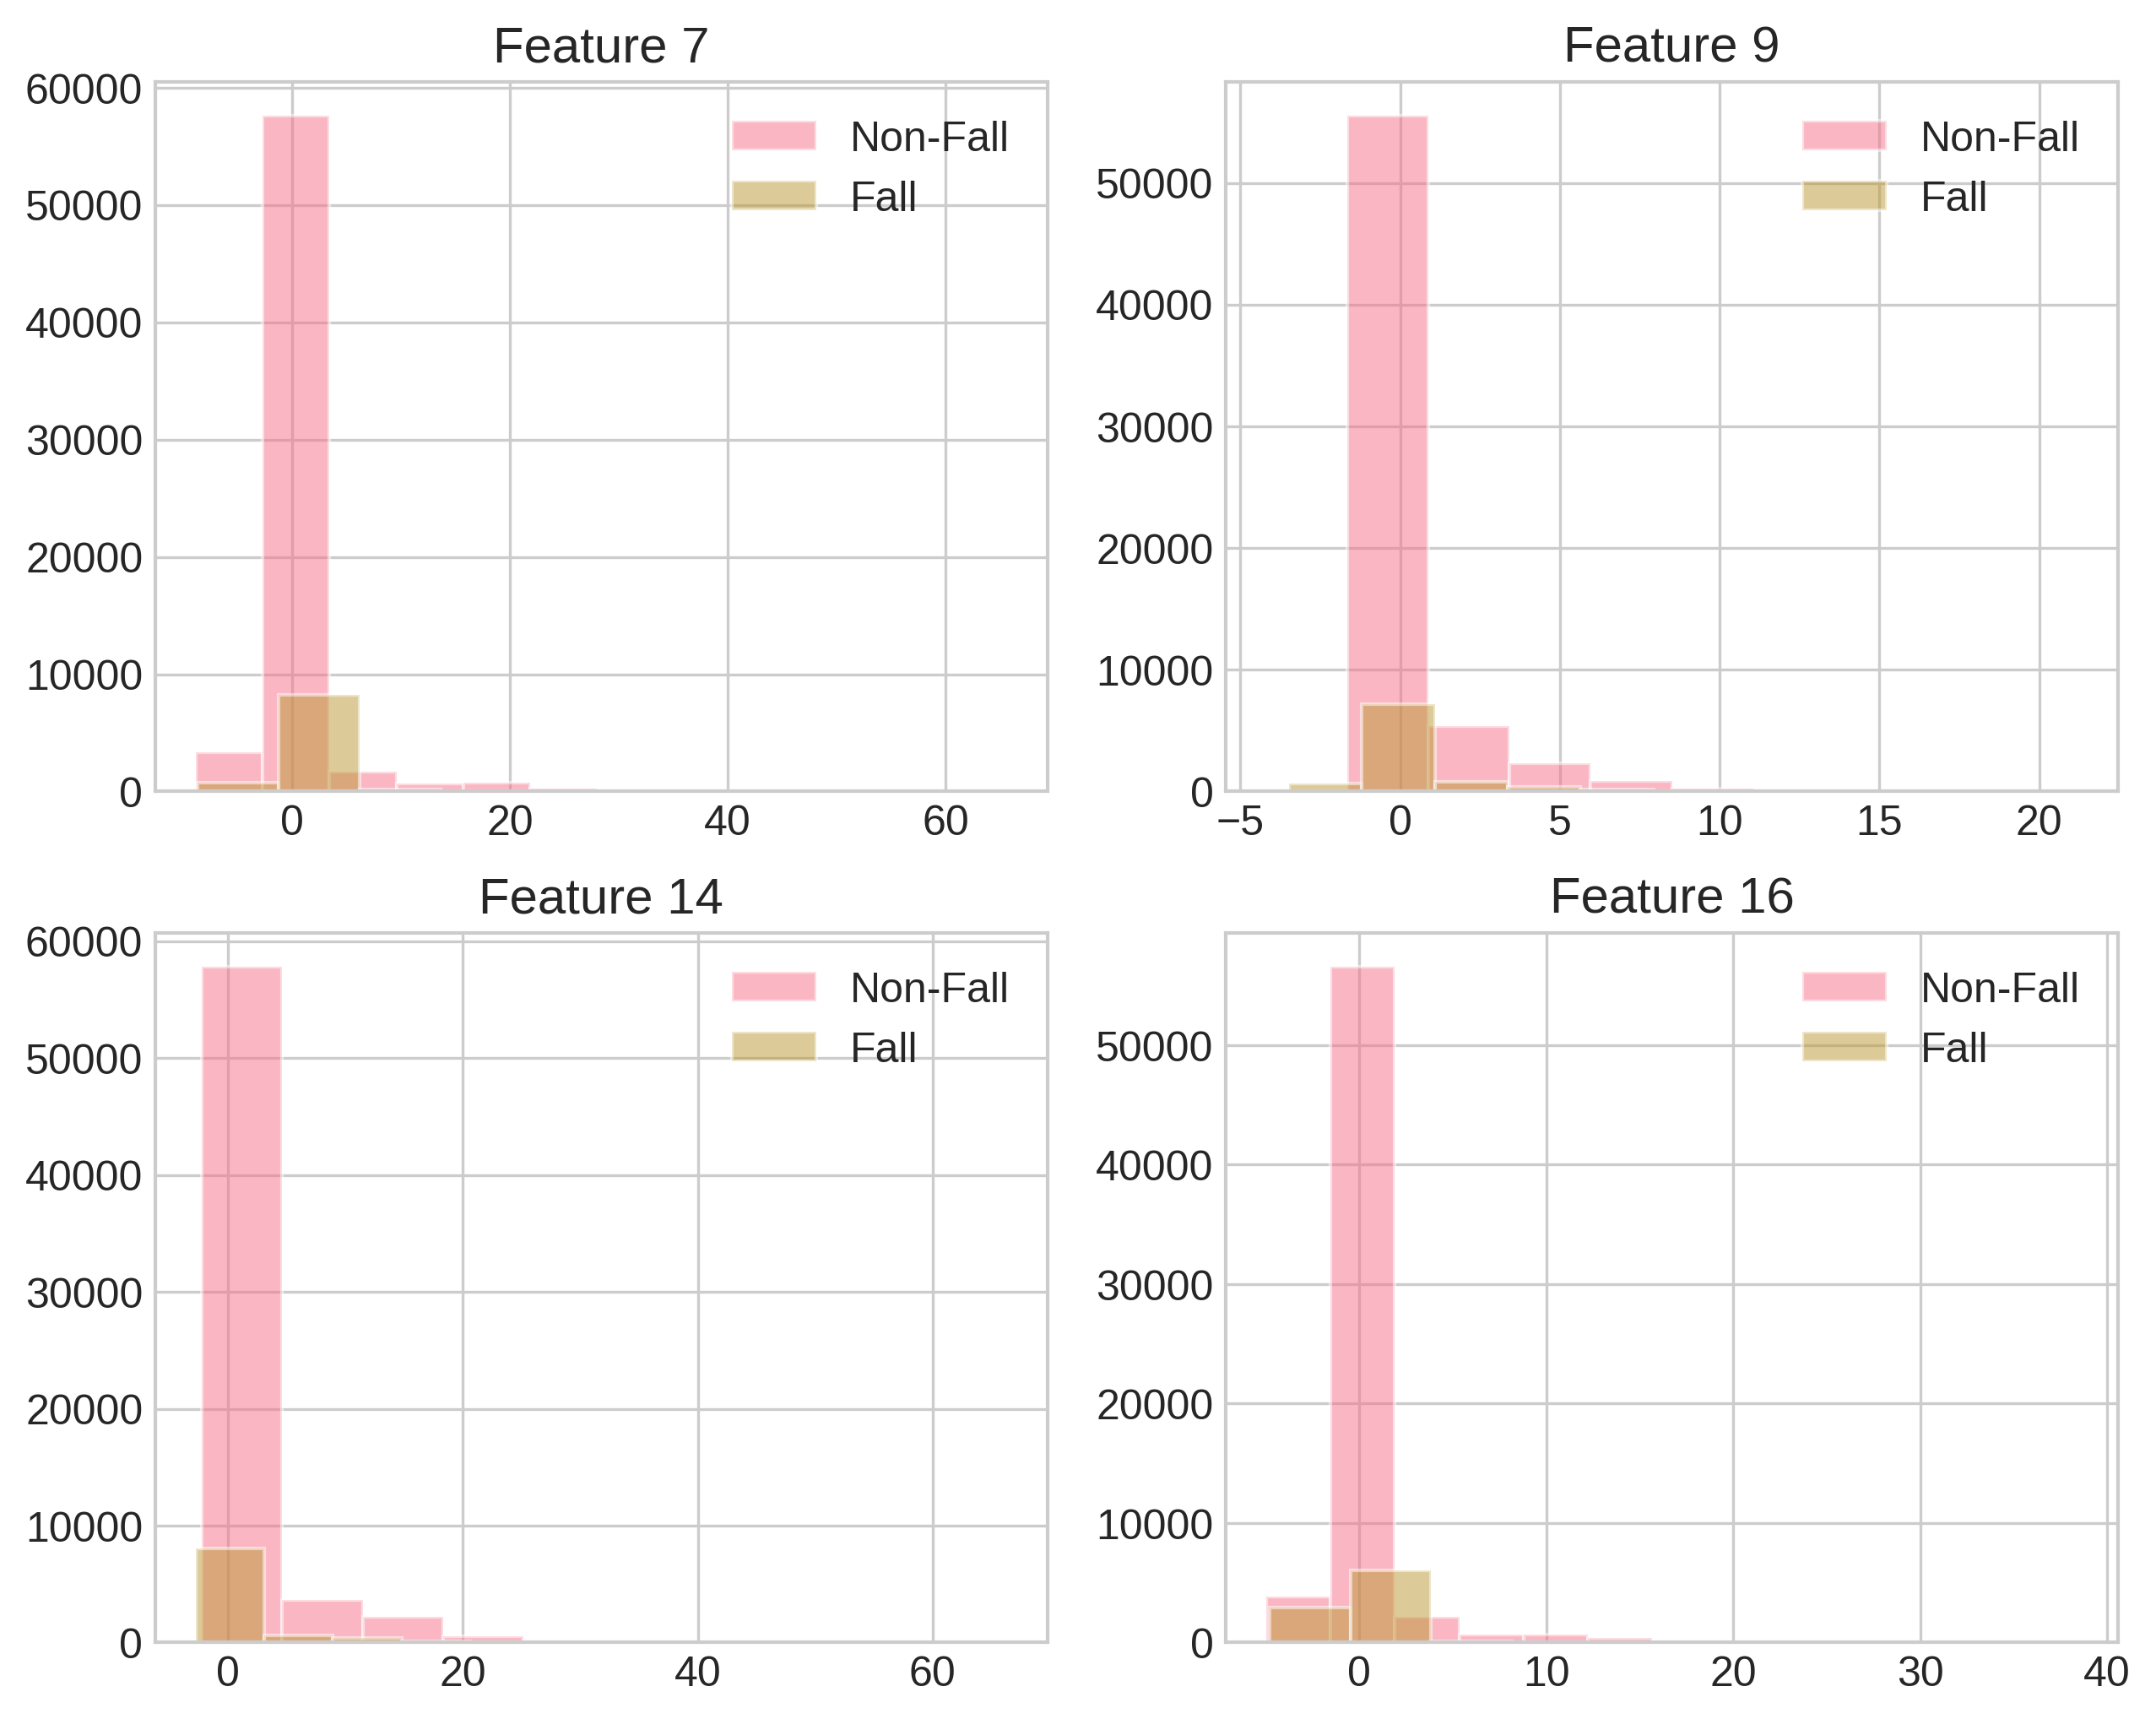

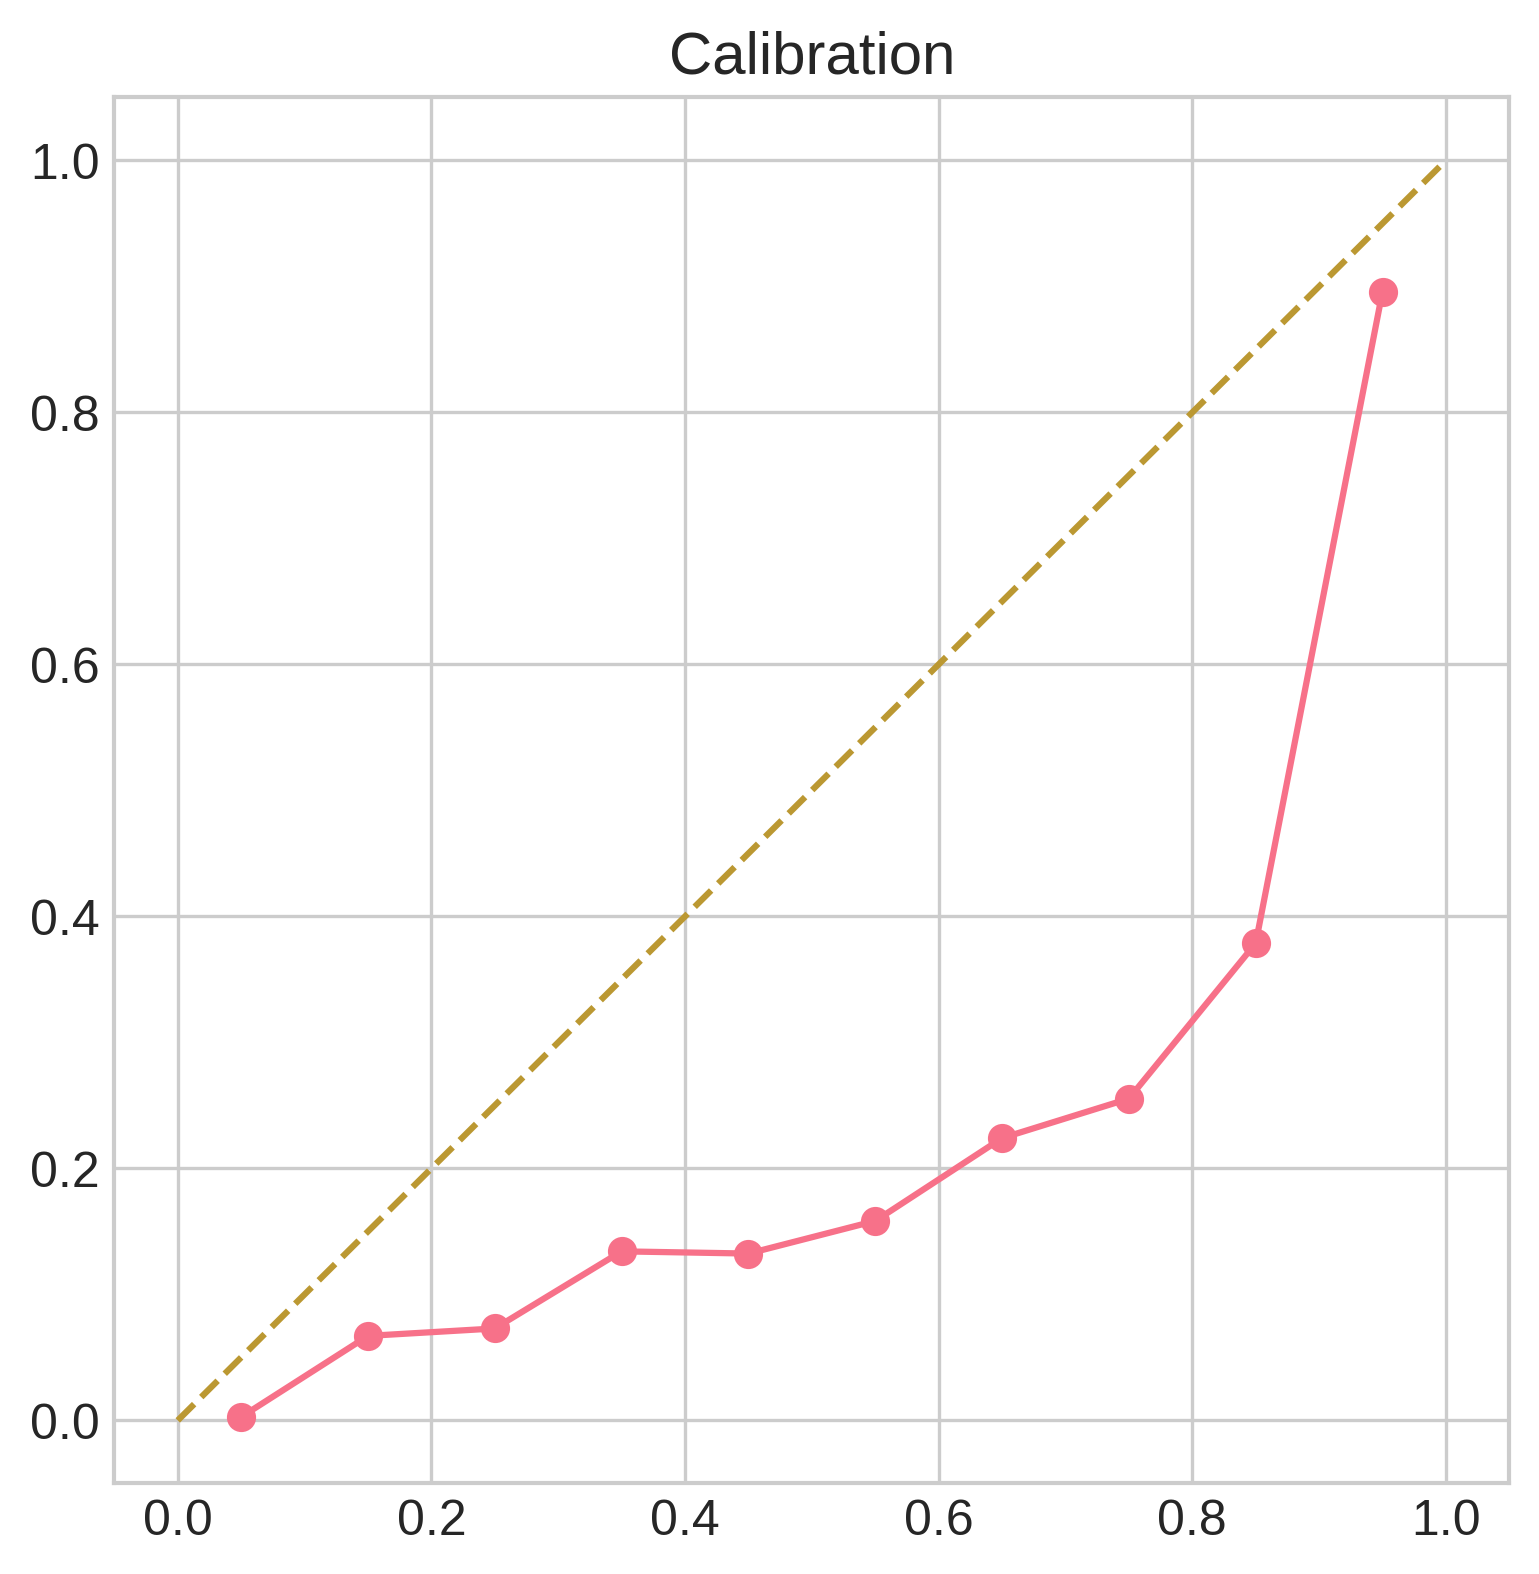


📊 METRICS:
      Metric     Value
0   Accuracy  0.972621
1  Precision  0.885959
2     Recall  0.896627
3         F1  0.891261
4    ROC-AUC  0.992825

📋 Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.98     64451
           1       0.89      0.90      0.89      9219

    accuracy                           0.97     73670
   macro avg       0.94      0.94      0.94     73670
weighted avg       0.97      0.97      0.97     73670



In [6]:
# =============================================================================
# RESEARCH PAPER EVALUATION - FINAL (FULL + FIXED)
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import time

from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, classification_report, roc_curve, auc,
    precision_recall_curve, PrecisionRecallDisplay
)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Ensure numpy format (FIX FOR ERROR)
y_test = np.array(y_test)

# Styling
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams.update({'font.size': 12, 'figure.dpi': 300, 'savefig.bbox': 'tight'})

print("Generating research paper figures (FINAL FIXED)...")

# =============================================================================
# CORE METRICS
# =============================================================================
y_proba = model.predict(X_test, verbose=0)[:, 1]
y_pred = (y_proba > 0.30).astype(int)

# =============================================================================
# FEATURE IMPORTANCE (FIXED)
# =============================================================================
print("\n🔍 FEATURE IMPORTANCE")

subset_idx = np.random.choice(len(X_test), size=5000, replace=False)
X_subset = X_test[subset_idx]
y_subset = y_test[subset_idx]

base_preds = (model.predict(X_subset, verbose=0)[:,1] > 0.3).astype(int)
base_score = accuracy_score(y_subset, base_preds)

importances = []

for i in range(X_subset.shape[1]):
    X_temp = X_subset.copy()
    np.random.shuffle(X_temp[:, i])
    
    preds = (model.predict(X_temp, verbose=0)[:,1] > 0.3).astype(int)
    score = accuracy_score(y_subset, preds)
    
    importances.append(base_score - score)

importances = np.array(importances)

plt.figure(figsize=(10,6))
plt.bar(range(len(importances)), importances)
plt.title("Feature Importance (Permutation)")
plt.xlabel("Feature Index")
plt.ylabel("Importance")
plt.savefig("fig_feature_importance.png", dpi=300)
plt.show()
print("✓ Feature importance saved")

# =============================================================================
# PCA CLUSTER
# =============================================================================
print("\n📉 PCA CLUSTER")

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_subset)

plt.figure(figsize=(8,6))
plt.scatter(X_pca[y_subset==0,0], X_pca[y_subset==0,1], alpha=0.3, label="Non-Fall")
plt.scatter(X_pca[y_subset==1,0], X_pca[y_subset==1,1], alpha=0.3, label="Fall")
plt.legend()
plt.title("PCA Cluster Plot")
plt.savefig("fig_pca_clusters.png", dpi=300)
plt.show()

# =============================================================================
# t-SNE CLUSTER (SAFE)
# =============================================================================
print("\n📉 t-SNE CLUSTER")

tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X_subset[:2000])   # LIMIT → avoid crash

plt.figure(figsize=(8,6))
plt.scatter(X_tsne[y_subset[:2000]==0,0], X_tsne[y_subset[:2000]==0,1], alpha=0.3, label="Non-Fall")
plt.scatter(X_tsne[y_subset[:2000]==1,0], X_tsne[y_subset[:2000]==1,1], alpha=0.3, label="Fall")
plt.legend()
plt.title("t-SNE Cluster Plot")
plt.savefig("fig_tsne_clusters.png", dpi=300)
plt.show()

# =============================================================================
# LATENCY
# =============================================================================
print("\n⚡ LATENCY")

sample = X_test[:1000]

start = time.time()
_ = model.predict(sample, verbose=0)
end = time.time()

latency = (end - start) / len(sample)
print(f"Latency per sample: {latency*1000:.4f} ms")

with open("latency.txt", "w") as f:
    f.write(f"{latency*1000:.4f} ms")

# =============================================================================
# THRESHOLD OPTIMIZATION
# =============================================================================
prec, rec, thresholds = precision_recall_curve(y_test, y_proba)
f1_scores = 2 * prec * rec / (prec + rec + 1e-8)
optimal_idx = np.argmax(f1_scores)
optimal_threshold = thresholds[optimal_idx]

y_pred_opt = (y_proba > optimal_threshold).astype(int)

print(f"Optimal threshold: {optimal_threshold:.3f}")

# =============================================================================
# CONFUSION MATRIX
# =============================================================================
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred_opt)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Non-Fall', 'Fall'], 
            yticklabels=['Non-Fall', 'Fall'])

plt.title(f'Confusion Matrix (Acc={accuracy_score(y_test, y_pred_opt):.2%})')
plt.savefig('fig1a_confusion_matrix.png')
plt.show()

# =============================================================================
# ROC CURVE
# =============================================================================
plt.figure(figsize=(8, 6))
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, lw=2, label=f'AUC = {roc_auc:.3f}')
plt.plot([0,1],[0,1],'--')

plt.title('ROC Curve')
plt.legend()
plt.savefig('fig1b_roc_curve.png')
plt.show()

# =============================================================================
# PR CURVE
# =============================================================================
plt.figure(figsize=(8, 6))
PrecisionRecallDisplay.from_predictions(y_test, y_proba)
plt.savefig('fig1c_precision_recall.png')
plt.show()

# =============================================================================
# THRESHOLD PLOT
# =============================================================================
plt.figure(figsize=(10, 6))
plt.plot(thresholds, f1_scores[:-1])
plt.axvline(optimal_threshold, color='red')
plt.title('Threshold Optimization')
plt.savefig('fig1d_threshold_optimization.png')
plt.show()

# =============================================================================
# TRAINING CURVES
# =============================================================================
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Loss')

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Accuracy')

plt.savefig('fig2_training_curves.png')
plt.show()

# =============================================================================
# FEATURE DISTRIBUTIONS
# =============================================================================
plt.figure(figsize=(10,8))

for i, idx in enumerate([7,9,14,16]):
    plt.subplot(2,2,i+1)
    plt.hist(X_test[y_test==0, idx], alpha=0.5, label='Non-Fall')
    plt.hist(X_test[y_test==1, idx], alpha=0.5, label='Fall')
    plt.title(f'Feature {idx}')
    plt.legend()

plt.savefig('fig3_feature_distributions.png')
plt.show()

# =============================================================================
# CALIBRATION
# =============================================================================
plt.figure(figsize=(6,6))

bins = np.linspace(0,1,11)
bin_centers = (bins[:-1]+bins[1:])/2

frac = []
for i in range(len(bins)-1):
    mask = (y_proba>=bins[i]) & (y_proba<bins[i+1])
    frac.append(np.mean(y_test[mask]) if np.sum(mask)>0 else 0)

plt.plot(bin_centers, frac, marker='o')
plt.plot([0,1],[0,1],'--')

plt.title('Calibration')
plt.savefig('fig4_calibration_distribution.png')
plt.show()

# =============================================================================
# METRICS TABLE
# =============================================================================
metrics_table = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC'],
    'Value': [
        accuracy_score(y_test, y_pred_opt),
        precision_score(y_test, y_pred_opt),
        recall_score(y_test, y_pred_opt),
        f1_score(y_test, y_pred_opt),
        roc_auc
    ]
})

print("\n📊 METRICS:")
print(metrics_table)

metrics_table.to_latex('table1_metrics.tex', index=False)

# =============================================================================
# REPORT
# =============================================================================
print("\n📋 Classification Report:")
print(classification_report(y_test, y_pred_opt))

In [7]:
# ============================================
# 7. DEPLOYMENT ARTIFACTS (FULL RESEARCH VERSION)
# ============================================

print("\n🔧 Exporting deployment artifacts...")

# Save full precision
model.save('production_fall_final.h5')

fp32_size = os.path.getsize('production_fall_final.h5') / 1024

# FLOAT16
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_types = [tf.float16]
tflite_fp16 = converter.convert()

with open('production_fall_fp16.tflite', 'wb') as f:
    f.write(tflite_fp16)

fp16_size = os.path.getsize('production_fall_fp16.tflite') / 1024

# INT8
def representative_dataset_gen():
    for i in range(200):
        yield [np.array([X_train_aug[i]], dtype=np.float32)]

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset_gen
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

tflite_int8 = converter.convert()

with open('production_fall_int8.tflite', 'wb') as f:
    f.write(tflite_int8)

int8_size = os.path.getsize('production_fall_int8.tflite') / 1024

# Save scaler
joblib.dump(scaler, 'production_fall_scaler.pkl')

# ============================================
# SIZE COMPARISON TABLE
# ============================================
size_table = pd.DataFrame({
    "Model": ["FP32 (Keras)", "FP16 (TFLite)", "INT8 (TFLite)"],
    "Size (KB)": [fp32_size, fp16_size, int8_size]
})

print("\n📦 MODEL SIZE COMPARISON")
print(size_table)

size_table.to_csv("model_sizes.csv", index=False)

# ============================================
# SUMMARY
# ============================================
print(f"\n✅ COMPLETE DEPLOYMENT PACKAGE:")
print(f"  Model: production_fall_final.h5 ({fp32_size:.0f} KB)")
print(f"  TFLite FP16: production_fall_fp16.tflite ({fp16_size:.0f} KB)")
print(f"  TFLite INT8: production_fall_int8.tflite ({int8_size:.0f} KB)")
print(f"  Scaler: production_fall_scaler.pkl")
print(f"  Threshold: 0.30")
print(f"  Input: 24 floats → Output: [ADL_prob, FALL_prob]")

print("\n🚀 DEPLOYMENT READY!")


🔧 Exporting deployment artifacts...
Saved artifact at '/tmp/tmpwjsid3td'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 24), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  134109395746064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134109395738768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134109395744720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134109395745296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134109395745872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134109395745104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134109395744912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134109395739152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134109395745488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134109395746640: TensorSpec(shape=(), dtype=tf.resource,

W0000 00:00:1775318428.004015      19 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1775318428.004068      19 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.
I0000 00:00:1775318428.025973      19 mlir_graph_optimization_pass.cc:401] MLIR V1 optimization pass is not enabled


Saved artifact at '/tmp/tmpficzjkvq'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 24), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  134109395746064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134109395738768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134109395744720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134109395745296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134109395745872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134109395745104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134109395744912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134109395739152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134109395745488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134109395746640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134109395739344: Tensor

/usr/local/lib/python3.11/dist-packages/tensorflow/lite/python/convert.py:997: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1775318432.483843      19 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1775318432.483878      19 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.



📦 MODEL SIZE COMPARISON
           Model    Size (KB)
0   FP32 (Keras)  1049.289062
1  FP16 (TFLite)   168.714844
2  INT8 (TFLite)   109.031250

✅ COMPLETE DEPLOYMENT PACKAGE:
  Model: production_fall_final.h5 (1049 KB)
  TFLite FP16: production_fall_fp16.tflite (169 KB)
  TFLite INT8: production_fall_int8.tflite (109 KB)
  Scaler: production_fall_scaler.pkl
  Threshold: 0.30
  Input: 24 floats → Output: [ADL_prob, FALL_prob]

🚀 DEPLOYMENT READY!


fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8


In [8]:
# ============================================
# FEATURE PRUNING + RETRAINING COMPARISON
# ============================================

print("\n🚀 FEATURE PRUNING EXPERIMENT")

# -------------------------------
# 1. SELECT LOW IMPORTANCE FEATURES
# -------------------------------
threshold = 0.01   # you can tune this
low_features = np.where(importances < threshold)[0]

print(f"Low importance features (to remove): {low_features}")
print(f"Original feature count: {X_train_aug.shape[1]}")
print(f"Reduced feature count: {X_train_aug.shape[1] - len(low_features)}")

# -------------------------------
# 2. CREATE REDUCED DATASETS
# -------------------------------
X_train_red = np.delete(X_train_aug, low_features, axis=1)
X_val_red   = np.delete(X_val, low_features, axis=1)
X_test_red  = np.delete(X_test, low_features, axis=1)

# -------------------------------
# 3. CREATE NEW MODEL
# -------------------------------
model_red = create_industrial_model(X_train_red.shape[1])

callbacks_red = [
    ModelCheckpoint('industrial_fall_reduced.h5', monitor='val_accuracy', save_best_only=True, mode='max'),
    EarlyStopping(monitor='val_accuracy', patience=20, restore_best_weights=True)
]

print("\n🔁 Training REDUCED model...")

history_red = model_red.fit(
    X_train_red, Y_train,
    epochs=120,
    batch_size=1024,
    validation_data=(X_val_red, Y_val),
    class_weight=class_weights,
    callbacks=callbacks_red,
    verbose=1
)

model_red.load_weights('industrial_fall_reduced.h5')

# -------------------------------
# 4. EVALUATE BOTH MODELS
# -------------------------------

print("\n📊 COMPARING ORIGINAL vs REDUCED")

# ORIGINAL
y_proba_orig = model.predict(X_test, verbose=0)[:,1]
y_pred_orig = (y_proba_orig > 0.30).astype(int)

# REDUCED
y_proba_red = model_red.predict(X_test_red, verbose=0)[:,1]
y_pred_red = (y_proba_red > 0.30).astype(int)

# Metrics
def get_metrics(y_true, y_pred, y_proba):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "ROC-AUC": auc(*roc_curve(y_true, y_proba)[:2])
    }

metrics_orig = get_metrics(y_test, y_pred_orig, y_proba_orig)
metrics_red  = get_metrics(y_test, y_pred_red, y_proba_red)

# -------------------------------
# 5. CREATE COMPARISON TABLE
# -------------------------------
comparison = pd.DataFrame([metrics_orig, metrics_red],
                          index=["Original (24F)", "Reduced"])

print("\n📊 PERFORMANCE COMPARISON:")
print(comparison)

comparison.to_csv("feature_pruning_comparison.csv")

# -------------------------------
# 6. SIZE COMPARISON
# -------------------------------
print("\n📦 MODEL SIZE COMPARISON")

model.save("model_original.h5")
model_red.save("model_reduced.h5")

size_orig = os.path.getsize("model_original.h5") / 1024
size_red  = os.path.getsize("model_reduced.h5") / 1024

print(f"Original Model Size: {size_orig:.2f} KB")
print(f"Reduced Model Size: {size_red:.2f} KB")

# -------------------------------
# 7. LATENCY COMPARISON
# -------------------------------
print("\n⚡ LATENCY COMPARISON")

def measure_latency(m, X):
    sample = X[:1000]
    start = time.time()
    _ = m.predict(sample, verbose=0)
    end = time.time()
    return (end - start) / len(sample)

lat_orig = measure_latency(model, X_test)
lat_red  = measure_latency(model_red, X_test_red)

print(f"Original latency: {lat_orig*1000:.4f} ms")
print(f"Reduced latency: {lat_red*1000:.4f} ms")

# -------------------------------
# 8. SAVE RESULTS
# -------------------------------
results_summary = pd.DataFrame({
    "Model": ["Original", "Reduced"],
    "Features": [X_train_aug.shape[1], X_train_red.shape[1]],
    "Size_KB": [size_orig, size_red],
    "Latency_ms": [lat_orig*1000, lat_red*1000],
    "F1": [metrics_orig["F1"], metrics_red["F1"]]
})

results_summary.to_csv("final_model_comparison.csv", index=False)

print("\n✅ Feature pruning experiment complete!")


🚀 FEATURE PRUNING EXPERIMENT
Low importance features (to remove): [12 13 15 19 21]
Original feature count: 24
Reduced feature count: 19

🔁 Training REDUCED model...
Epoch 1/120


2026-04-04 16:00:34.266431: E tensorflow/core/framework/node_def_util.cc:676] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_16}}


270/272 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5960 - loss: 1.1557

2026-04-04 16:00:45.922008: E tensorflow/core/framework/node_def_util.cc:676] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


272/272 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - accuracy: 0.5967 - loss: 1.1537 - val_accuracy: 0.7439 - val_loss: 0.5028
Epoch 2/120
272/272 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.7565 - loss: 0.7336 - val_accuracy: 0.8087 - val_loss: 0.3994
Epoch 3/120
272/272 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.8035 - loss: 0.6248 - val_accuracy: 0.8273 - val_loss: 0.3482
Epoch 4/120
272/272 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.8264 - loss: 0.5620 - val_accuracy: 0.8340 - val_loss: 0.3328
Epoch 5/120
272/272 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.8379 - loss: 0.5167 - val_accuracy: 0.8450 - val_loss: 0.3115
Epoch 6/120
272/272 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.8513 - loss: 0.4805 - val_accuracy: 0.8600 - val_loss: 0.3020
Epoch 7/120
272/272 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.8627 - loss: 0.4468 - val_accuracy: 0.8617 - val_loss: 0.2883
Epoch 8/120
272/272 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.8701 - loss: 0.4199 - val_accurac

2026-04-04 16:08:18.049509: E tensorflow/core/framework/node_def_util.cc:676] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-04-04 16:08:23.599420: E tensorflow/core/framework/node_def_util.cc:676] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),


📊 PERFORMANCE COMPARISON:
                Accuracy  Precision    Recall        F1   ROC-AUC
Original (24F)  0.950387   0.725008  0.972340  0.830654  0.992825
Reduced         0.948337   0.716572  0.971363  0.824738  0.992441

📦 MODEL SIZE COMPARISON
Original Model Size: 1049.29 KB
Reduced Model Size: 1041.73 KB

⚡ LATENCY COMPARISON


2026-04-04 16:08:30.095302: E tensorflow/core/framework/node_def_util.cc:676] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


Original latency: 0.1745 ms
Reduced latency: 0.1664 ms

✅ Feature pruning experiment complete!
